# 06 — Three MC SR significance candidates and VR2 validation (4mu)

Fix the three boundary WPs selected from the nominal **MC SR** and apply the same boundaries to **VR2 PP · DP · PD**.
The reference is **(mu iso, |Δφ|)=(0.30, 2.6)**. First compare the reference with the three candidates,
then present each WP's distributions, ABCD yields, scans, correlations, and MC SR results in the style of notebooks 03 and 04.

| Candidate | Mu isolation boundary | Δφ boundary [rad] |
|---|---:|---:|
| WP1 | 0.30 | 2.4 |
| WP2 | 0.25 | 2.4 |
| WP3 | 0.40 | 2.4 |

**Nominal DATA A remains blinded. Nominal DATA is neither projected nor aggregated.**
Do not add DD to VR2 or use an inclusive displacement selection.
The candidates are three previously chosen MC-based points; this notebook does not reselect them using VR DATA closure.

Run with `Restart → Run All`. Read the original coffea inputs once per channel and partition the same plane at the three WPs.
For each WP, update the SR and VR boundaries, fixed-axis scans, composition, and correlations together.


In [1]:
from pathlib import Path
import sys

SIDM_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if p.name == "sidm"), None)
if SIDM_DIR is None:
    raise RuntimeError("Run this notebook from inside the sidm repository.")
if str(SIDM_DIR.parent) not in sys.path:
    sys.path.insert(0, str(SIDM_DIR.parent))
NOTEBOOK_DIR = SIDM_DIR / "studies" / "ABCD_finalize"
INPUT_DIR = SIDM_DIR / "studies" / "ABCD_plane_summary"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

# Import coffea/pyarrow before defining NumPy 2 pickle compatibility aliases.
import coffea.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
if int(np.__version__.split(".")[0]) < 2:
    import numpy.core as _numpy_core
    import numpy.core.multiarray as _numpy_multiarray
    import numpy.core.numeric as _numpy_numeric
    sys.modules.setdefault("numpy._core", _numpy_core)
    sys.modules.setdefault("numpy._core.multiarray", _numpy_multiarray)
    sys.modules.setdefault("numpy._core.numeric", _numpy_numeric)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "pdf.fonttype": 42,
                     "figure.max_open_warning": 0})
pd.set_option("display.max_columns", 20)

for helper in ("abcd_finalize_common.py", "abcd_finalize_plots.py",
               "abcd_finalize_common.py", "abcd_finalize_common.py"):
    if not (NOTEBOOK_DIR / helper).is_file():
        raise FileNotFoundError(NOTEBOOK_DIR / helper)
from abcd_finalize_common import finalize_wp_comparison_run_wp_comparison as run_wp_comparison, finalize_wp_comparison_make_wp_figures as make_wp_figures, finalize_wp_comparison_export_wp_comparison as export_wp_comparison

# Display notebook PNGs regardless of the significance helper's batch backend.
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "pdf.fonttype": 42,
                     "figure.max_open_warning": 0})


## 1. Selections and fixed candidates

| Purpose | Displacement | Mjj [GeV] | Partner isolation |
|---|---|---|---|
| Nominal MC SR | DD | ≥150 | 0≤iso<0.5 |
| VR2 | PP · DP · PD | 150≤Mjj<300 | 0≤iso<0.5 |

LJ0 is the leading mu-LJ and LJ1 is the subleading mu-LJ. For both LJs, P means max pixel hits>2 and D means ≤2. Do not reorder the LJs.

**A=low iso/high Δφ**, B=high/high, C=low/low, and D=high/low.
A is defined by `iso < tx` and `|Δφ| ≥ ty`; boundary values belong to the high side.
There is no additional Δφ event precut. Mass intervals include the lower bound and exclude the upper bound.
The (0.30, 2.6) values in `CONFIG` are used to calculate the original reference; the actual candidates are listed in `WORKING_POINTS`.


In [2]:
TOPOLOGY = '4mu'
VR = 'VR2'
NOTEBOOK_NAME = '06_MuIso_DPhi_4mu_WP_comparison.ipynb'
OUTPUT_DIR = NOTEBOOK_DIR / '06_4mu_WP_comparison_outputs'
CONFIG = {
    'topology': TOPOLOGY, 'vr': VR, 'candidate_order': ['PP', 'DP', 'PD'],
    'output_dir': OUTPUT_DIR,
    'notebook_path': NOTEBOOK_DIR / NOTEBOOK_NAME,
    'sr_reference_dir': INPUT_DIR / '12_Optimized_ABCD_4mu_comparison_outputs',
    'bkg_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_bkg_merged_samples_v1',
    'signal_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_signal_merged_samples_v1',
    'data_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_data_merged_samples_v1',
    'current_hist': 'abcd6d_' + TOPOLOGY,
    'expected_current_channel': 'abcd6d_inclusive_' + TOPOLOGY + '_dxySpread_cosAlpha_mu_veto_eHEM',
    'mass_min': 150.0, 'mass_max': 300.0,
    'partner_iso_low': 0., 'partner_iso_high': .5,
    'tx': .3, 'ty': 2.6,
    'scan_mu_iso': [.05, .1, .15, .2, .25, .3, .4, .5, .75, 1., 2.],
    'scan_abs_dphi': [.5, 1., 1.5, 2., 2.2, 2.4, 2.6, 2.7, 2.8, 2.9, 3., 3.05, 3.1, np.pi],
    'closure_band': (.9, 1.1), 'min_neff': 10., 'purity_limit': .10,
}
print('Channel:', TOPOLOGY, '| VR:', VR, '| Categories:', CONFIG['candidate_order'], '| Output:', OUTPUT_DIR)

WORKING_POINTS = [(0.3, 2.4), (0.25, 2.4), (0.4, 2.4)]
display(pd.DataFrame(WORKING_POINTS, columns=["mu_iso", "abs_dphi"],
                     index=["WP1", "WP2", "WP3"]))


Channel: 4mu | VR: VR2 | Categories: ['PP', 'DP', 'PD'] | Output: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_finalize/06_4mu_WP_comparison_outputs


,mu_iso,abs_dphi
WP1,0.30,2.4
WP2,0.25,2.4
WP3,0.40,2.4


## 2. Significance, blinding, and uncertainty definitions

For each signal hypothesis, use its nominal MC SR A yield as $S$ and the background MC yield in the same region as $B$.

$$ Z_A=\sqrt{2\left[(S+B)\ln(1+S/B)-S\right]}. $$

Evaluate the **60 signal hypotheses matching the channel** individually and compare WPs using the median of the per-hypothesis ratios $Z_A(\mathrm{WP})/Z_A(\mathrm{reference})$.
Do not sum signal hypotheses. Relative values remain undefined for hypotheses with reference Z=0.
Also inspect an effective on/off Asimov diagnostic using $\sigma_B^2=\sum w^2$.
The formulas follow [Cowan's counting-experiment note, Eqs. (10) and (20)](https://www.pp.rhul.ac.uk/~cowan/stat/medsig/medsigNote.pdf).
Keep the stored production normalization without rescaling cross sections.
This is not the discovery significance of the full ABCD likelihood. This sensitivity metric does not include closure nuisance parameters, signal MC uncertainties, or sideband signal leakage.

- **DATA WP gate:** Require $S/B_{MC}<0.10$ in each ABCD region for all 60 2Mu2E + 60 4Mu hypotheses spanning 200–1000 GeV. The background denominator must be valid and positive.
- **DATA 2D bin mask:** Using the same bins as the displayed plots, with the iso tail/overflow and angle flow merged, mask bins where the maximum $S/B_{MC}\geq0.10$ across the 120 signals or where MC support is invalid. Masked DATA is also excluded when determining the color scale.
- The bin mask is for displaying 2D distributions. ABCD yields and scans use the existing region-level gate and are not recalculated after removing masked bins.
- Show MC only in the MC SR. Do not calculate VR2 DD or nominal DATA.
- Display the iso scan over 0–2 and the Δφ scan over 0–π, using 11×14=154 native boundary points. Exclude the degenerate zero boundary from calculations.

As in notebooks 03 and 04, apply first-order uncertainty propagation for independent regions to $P=BC/D$ and $\kappa=A/P$.

$$\sigma_P=|P|\sqrt{(\sigma_B/B)^2+(\sigma_C/C)^2+(\sigma_D/D)^2},\qquad
\sigma_\kappa=|\kappa|\sqrt{(\sigma_A/A)^2+(\sigma_P/P)^2}.$$

For each region, $\sigma_X=\sqrt{\sum w^2}$ and $N_\mathrm{eff}=(\sum w)^2/\sum w^2$.
These formulas apply to positive, nonzero region yields. Leave D≤0 undefined,
and retain the existing zero-error convention for B or C=0 with a status flag. Do not interpret it as a precise zero prediction.
The green ±10% κ band is a reference range; nearby WPs and scan points share events.


## 3. Recalculation from original inputs and comparison with the reference

Recalculate the full MC SR and VR scans and purities using the original 18 backgrounds and 120 signals.
Process only approved VR DATA, then apply identical boundaries at each of the three fixed WPs.
Distinguish the 10–90% spread across signal hypotheses in the summary figures from statistical error bars.


In [3]:
results = run_wp_comparison(CONFIG, WORKING_POINTS)
tables = results['tables']
with pd.option_context('display.max_columns', None):
    display(results['working_points'])
    summary = tables['significance_summary']
    columns = [name for name in ['wp', 'tx', 'ty', 'b', 'sigma_b', 'neff_b',
                               'z_known_b_ratio_median', 'z_known_b_ratio_q10',
                               'z_known_b_ratio_q90', 'z_mc_stat_diagnostic_ratio_median']
               if name in summary]
    display(summary[columns])
    display(tables['distribution_blinding_summary'])
    display(tables['validation'])


MC 20/138 (18 backgrounds + 120 individual signal hypotheses)


MC 40/138 (18 backgrounds + 120 individual signal hypotheses)


MC 60/138 (18 backgrounds + 120 individual signal hypotheses)


MC 80/138 (18 backgrounds + 120 individual signal hypotheses)


MC 100/138 (18 backgrounds + 120 individual signal hypotheses)


MC 120/138 (18 backgrounds + 120 individual signal hypotheses)


... (5 outputs left out)

,wp,tx,ty
0,Reference,0.30,2.6
1,WP1,0.30,2.4
2,WP2,0.25,2.4
3,WP3,0.40,2.4


,wp,tx,ty,b,sigma_b,neff_b,z_known_b_ratio_median,z_known_b_ratio_q10,z_known_b_ratio_q90,z_mc_stat_diagnostic_ratio_median
0,Reference,0.30,2.6,3.253182,3.248042,1.003167,1.000000,1.000000,1.000000,1.000000
1,WP1,0.30,2.4,3.253182,3.248042,1.003167,1.024397,1.015200,1.042428,1.023191
2,WP2,0.25,2.4,3.253182,3.248042,1.003167,1.023688,1.015072,1.038047,1.022295
3,WP3,0.40,2.4,3.282356,3.248173,1.021159,1.020950,1.012746,1.041335,1.023659


,wp,plane,tx,ty,integrated_gate_approved,displayed_bins,approved_bins,blinded_bins,contamination_blinded_bins,unsupported_background_bins
0,Reference,PP,0.30,2.6,True,154,89,65,6,59
1,Reference,DP,0.30,2.6,True,154,30,124,3,121
2,Reference,PD,0.30,2.6,True,154,38,116,4,112
3,WP1,PP,0.30,2.4,True,154,89,65,6,59
4,WP1,DP,0.30,2.4,True,154,30,124,3,121
5,WP1,PD,0.30,2.4,True,154,38,116,4,112
6,WP2,PP,0.25,2.4,True,154,89,65,6,59
7,WP2,DP,0.25,2.4,True,154,30,124,3,121
8,WP2,PD,0.25,2.4,True,154,38,116,4,112
9,WP3,PP,0.40,2.4,True,154,89,65,6,59


,wp,plane,source,tx,ty,check,passed
0,WP1,PP,MC,0.30,2.4,Selected closure equals validated full grid,True
1,WP1,PP,DATA,0.30,2.4,Selected closure equals validated full grid,True
2,WP1,DP,MC,0.30,2.4,Selected closure equals validated full grid,True
3,WP1,DP,DATA,0.30,2.4,Selected closure equals validated full grid,True
4,WP1,PD,MC,0.30,2.4,Selected closure equals validated full grid,True
5,WP1,PD,DATA,0.30,2.4,Selected closure equals validated full grid,True
6,WP1,VR,MC / approved VR DATA,0.30,2.4,Scans hold the other selected WP boundary fixed,True
7,WP1,SR,MC / approved VR DATA,0.30,2.4,Scans hold the other selected WP boundary fixed,True
8,WP1,SR,MC,0.30,2.4,Same SR/VR WP; direct MC partition; no nominal...,True
9,WP2,PP,MC,0.25,2.4,Selected closure equals validated full grid,True


In [4]:
figures = make_wp_figures(results, CONFIG)
figure_lookup = {stem: figure for figure, stem in figures}
assert len(figures) == len(figure_lookup) == 66
summary_stems = [stem for _, stem in figures if not stem.startswith(('wp1_', 'wp2_', 'wp3_'))]
assert len(summary_stems) == 3
for figure, _ in figures:
    plt.close(figure)


### 3.1. MC SR sensitivity of the reference and three WPs


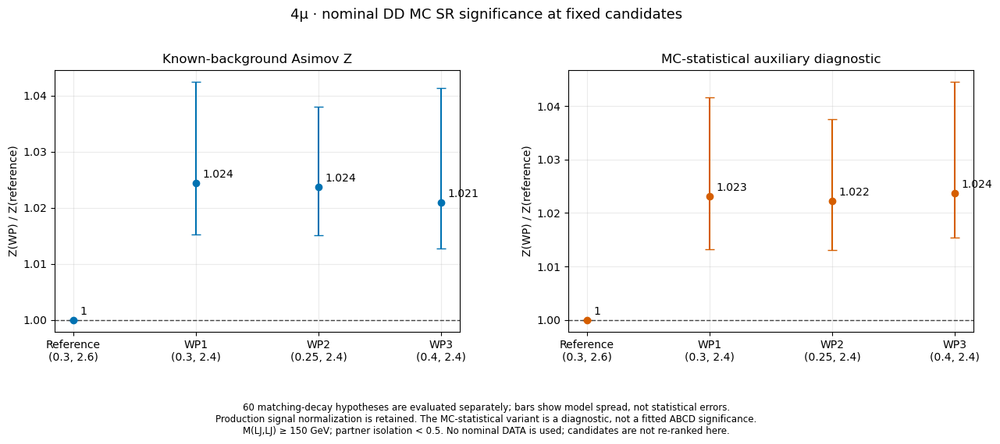

In [5]:
display(figure_lookup[summary_stems[0]])


### 3.2. Nominal MC SR statistical diagnostics


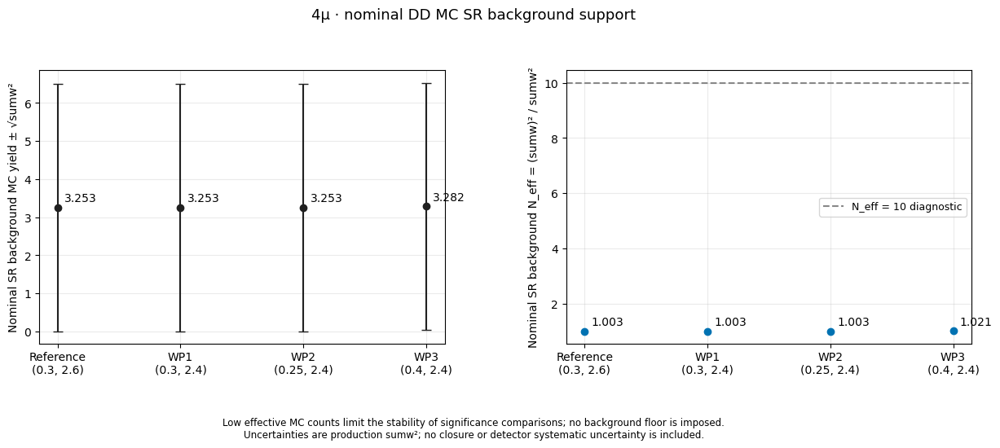

In [6]:
display(figure_lookup[summary_stems[1]])


### 3.3. VR2 closure comparison with identical boundaries


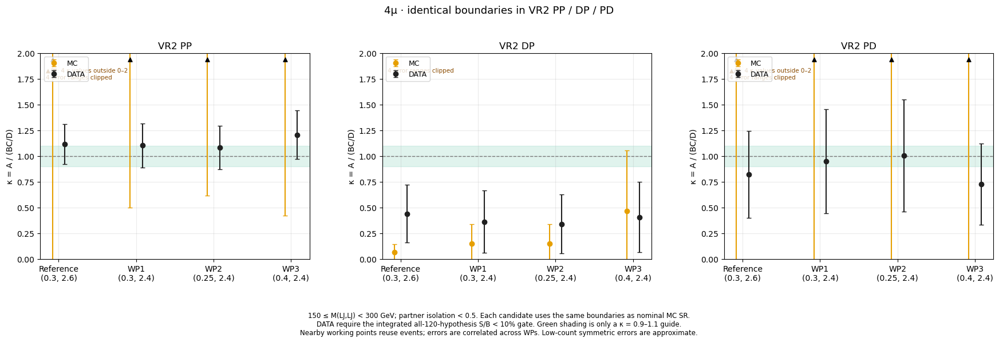

In [7]:
display(figure_lookup[summary_stems[2]])


## 4. WP1 — (mu iso, |Δφ|)=(0.30, 2.4)

Apply the **same (0.30, 2.4) boundaries to VR2 PP·DP·PD and the nominal MC SR** in this section.
Fix Δφ at **2.4** for the iso scan and iso at **0.30** for the Δφ scan.
The 154-point 2D κ maps share the same scan; only the selected-WP marker changes.


In [8]:
point = results['points']['WP1']
with pd.option_context('display.max_columns', None):
    display(point['tables']['selection'][['plane', 'state0', 'state1', 'mass_low',
                                         'mass_high', 'partner_iso_high', 'tx', 'ty']])
    display(point['tables']['closure'][['plane', 'source', 'A', 'B', 'C', 'D',
                                       'pred', 'pred_error', 'kappa', 'kappa_error',
                                       'neff_min', 'approved', 'status']])


,plane,state0,state1,mass_low,mass_high,partner_iso_high,tx,ty
0,PP,P,P,150.0,300.0,0.5,0.3,2.4
1,DP,D,P,150.0,300.0,0.5,0.3,2.4
2,PD,P,D,150.0,300.0,0.5,0.3,2.4


,plane,source,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,approved,status
0,PP,MC,446.223335,382.751786,17.618417,39.342512,171.404425,119.343943,2.603336,2.103916,5.070294,True,LOW_STAT_SIDEBAND
1,PP,DATA,285.000000,292.000000,61.000000,69.000000,258.144928,47.816673,1.104031,0.214704,61.000000,True,OK
2,DP,MC,13.085729,14.412884,3.283166,0.534523,88.527351,105.025837,0.147816,0.190100,1.021662,True,LOW_STAT_SIDEBAND
3,DP,DATA,38.000000,30.000000,7.000000,2.000000,105.000000,86.342342,0.361905,0.303333,2.000000,True,LOW_STAT_SIDEBAND
4,PD,MC,23.570281,4.503951,9.678727,16.560955,2.632246,3.215571,8.954436,11.619799,1.033877,True,LOW_STAT_SIDEBAND
5,PD,DATA,19.000000,20.000000,11.000000,11.000000,20.000000,9.629500,0.950000,0.506671,11.000000,True,OK


### 4.1. MC and DATA closure comparison at the fixed WP


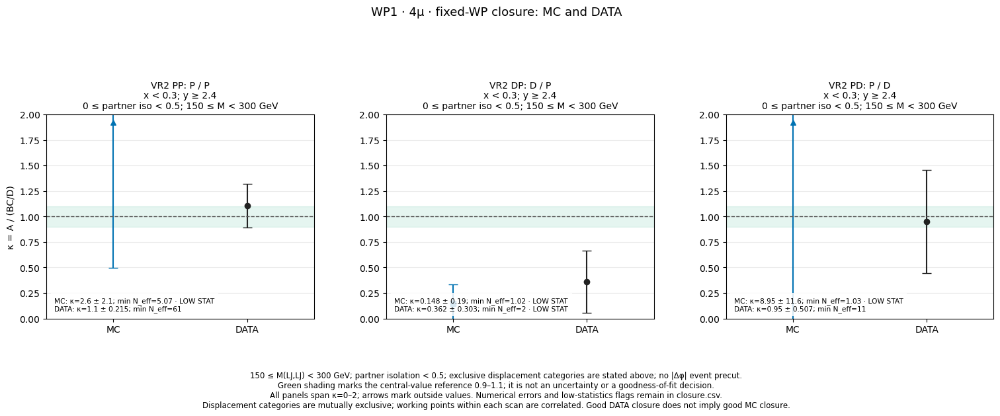

In [9]:
display(figure_lookup['wp1_combined_VR_selected_closure'])


### 4.2. Maximum S/B across 120 signals in each ABCD region


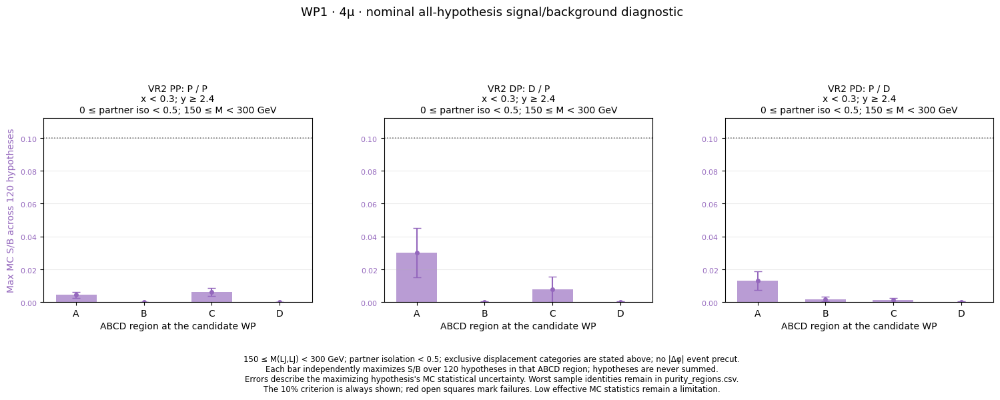

In [10]:
display(figure_lookup['wp1_mc_VR_purity_regions'])


### 4.3. DATA 2D distributions — per-bin blinding


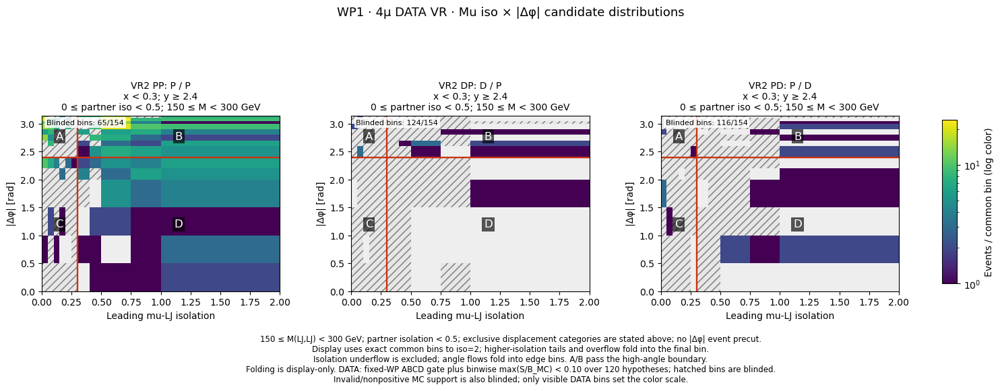

In [11]:
display(figure_lookup['wp1_data_VR_planes'])


### 4.4. DATA observed A, predicted BC/D, and κ


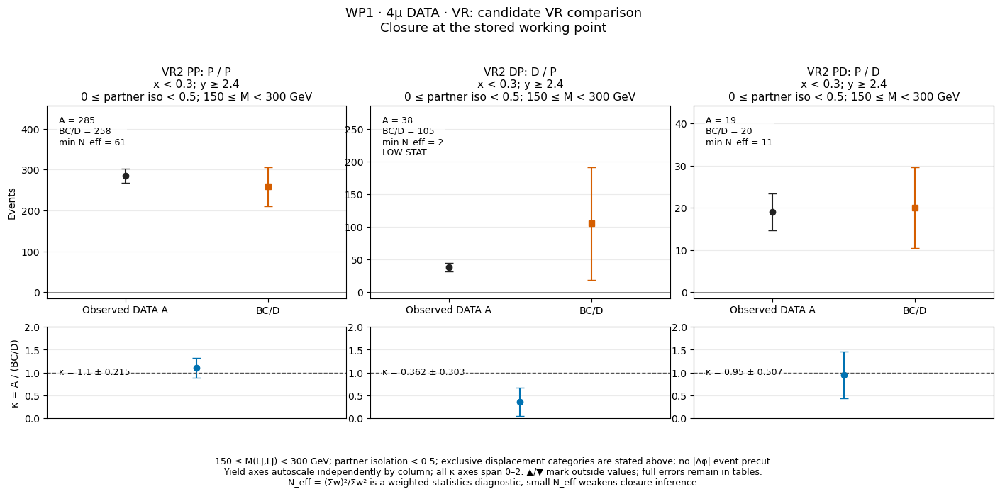

In [12]:
display(figure_lookup['wp1_data_VR_selected_closure'])


### 4.5. DATA isolation boundary scan


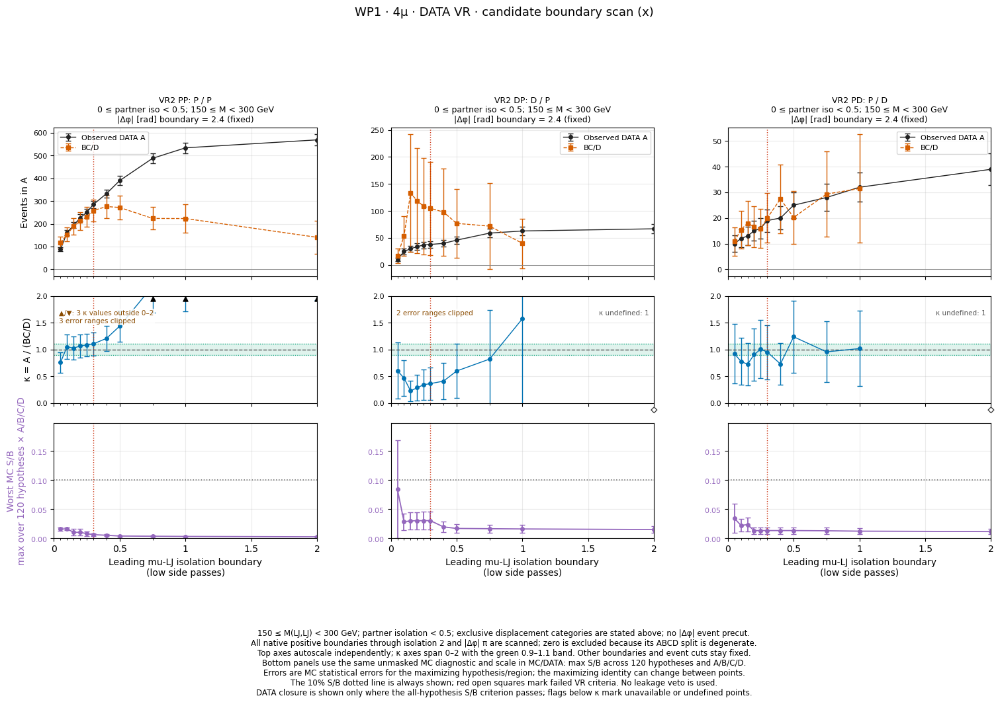

In [13]:
display(figure_lookup['wp1_data_VR_x_scan'])


### 4.6. DATA Δφ boundary scan


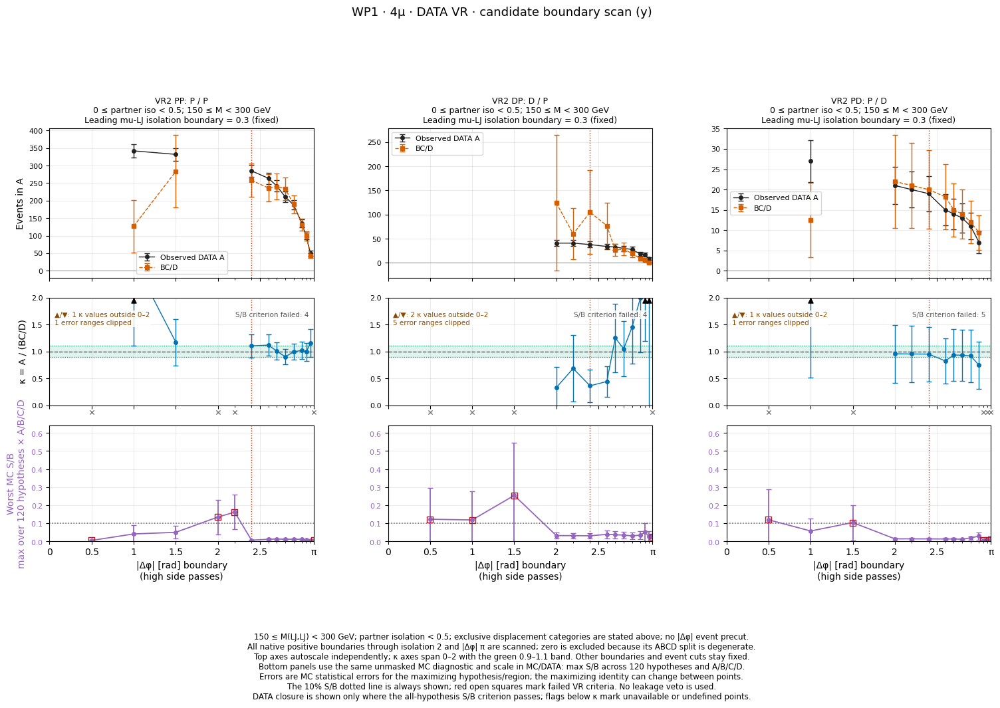

In [14]:
display(figure_lookup['wp1_data_VR_y_scan'])


### 4.7. DATA 154-point κ map


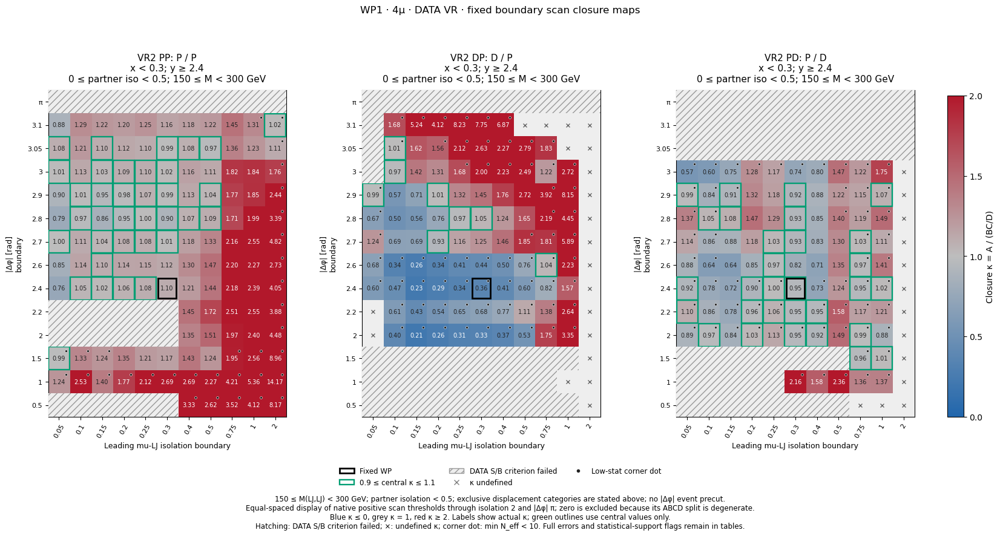

In [15]:
display(figure_lookup['wp1_data_VR_closure_grid'])


### 4.8. MC 2D distributions


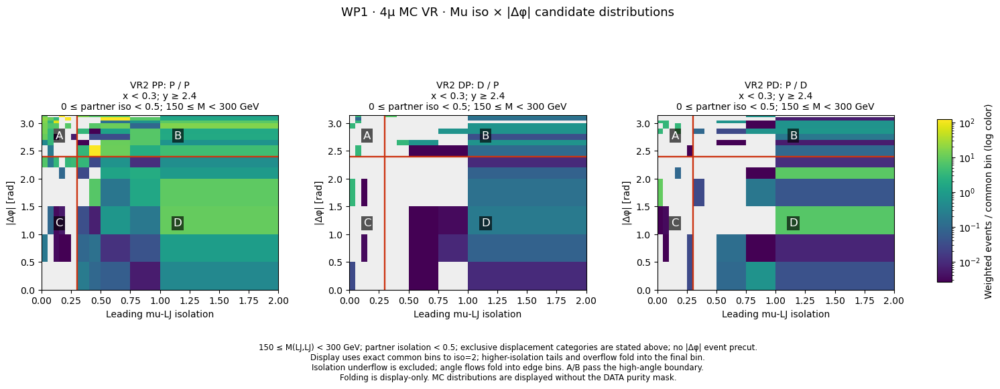

In [16]:
display(figure_lookup['wp1_mc_VR_planes'])


### 4.9. MC observed A, predicted BC/D, and κ


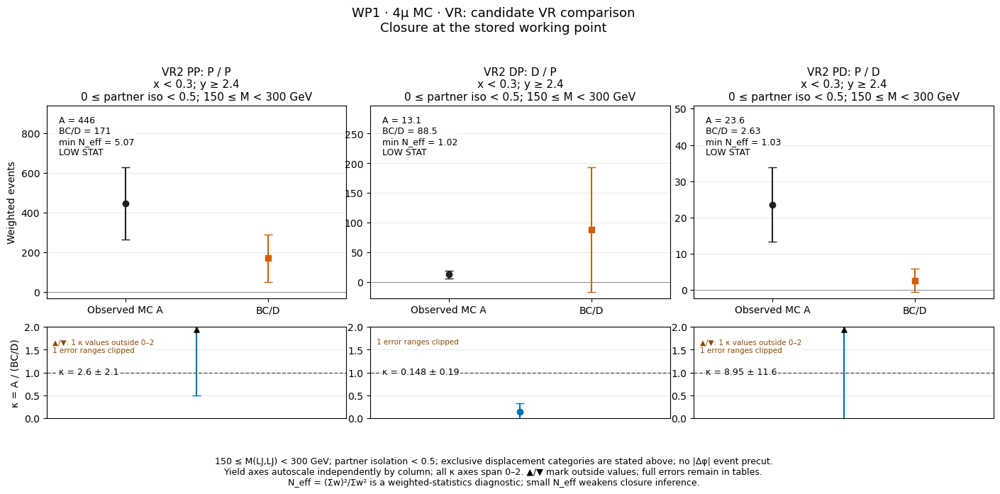

In [17]:
display(figure_lookup['wp1_mc_VR_selected_closure'])


### 4.10. MC isolation boundary scan


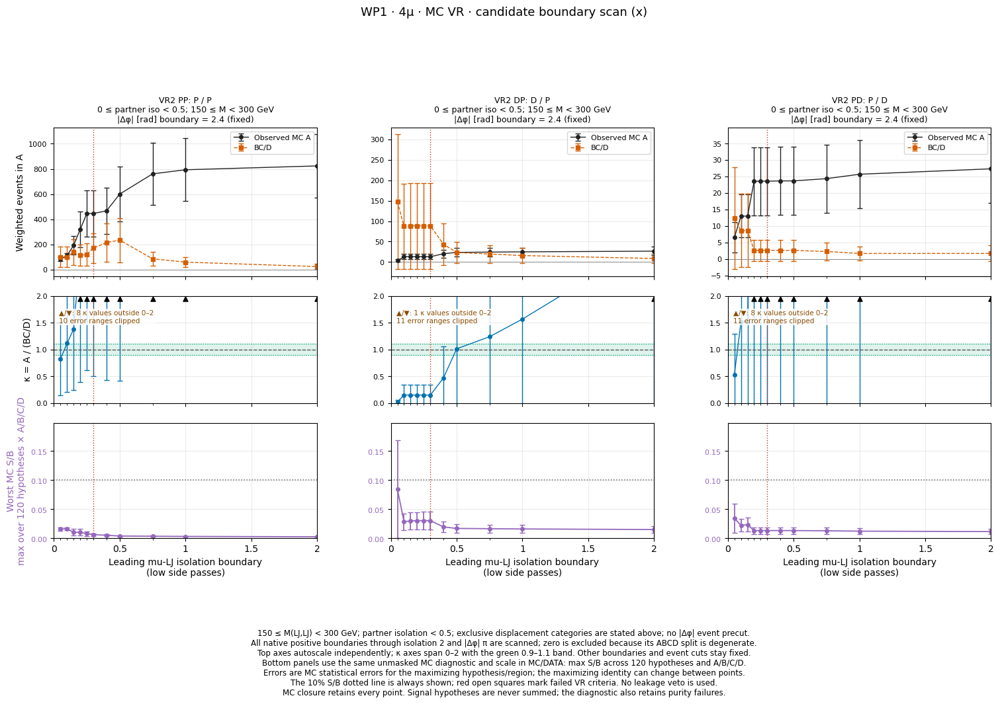

In [18]:
display(figure_lookup['wp1_mc_VR_x_scan'])


### 4.11. MC Δφ boundary scan


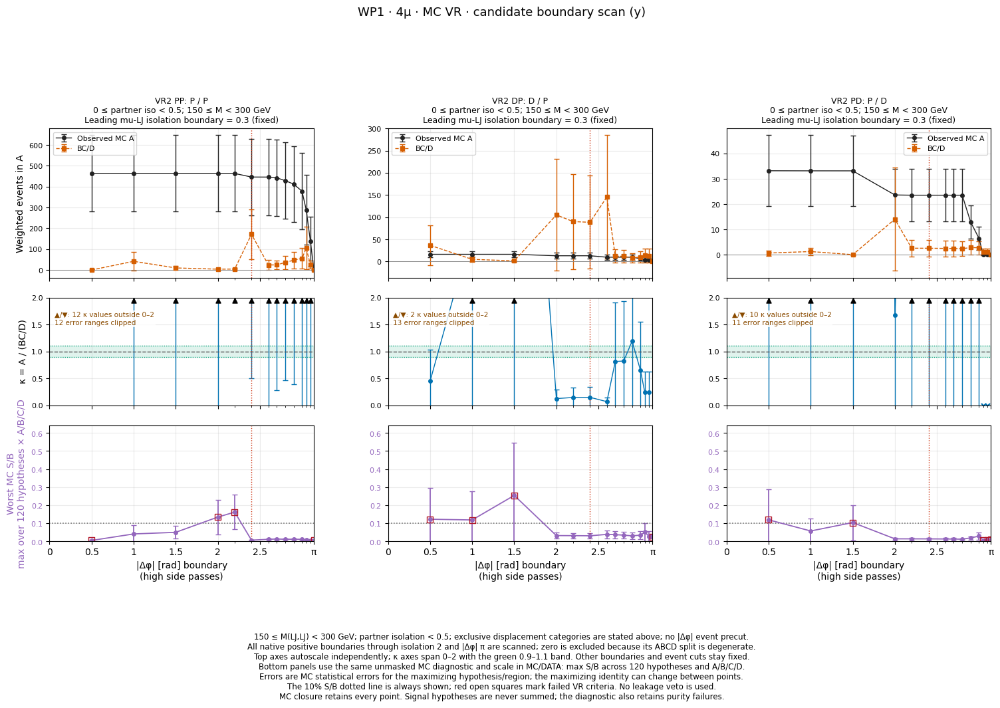

In [19]:
display(figure_lookup['wp1_mc_VR_y_scan'])


### 4.12. MC 154-point κ map


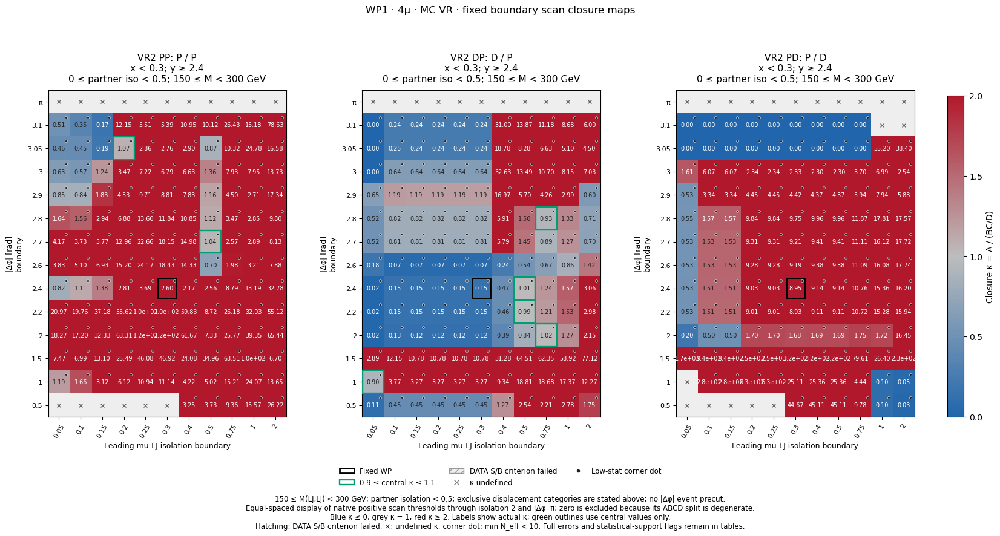

In [20]:
display(figure_lookup['wp1_mc_VR_closure_grid'])


### 4.13. MC background composition


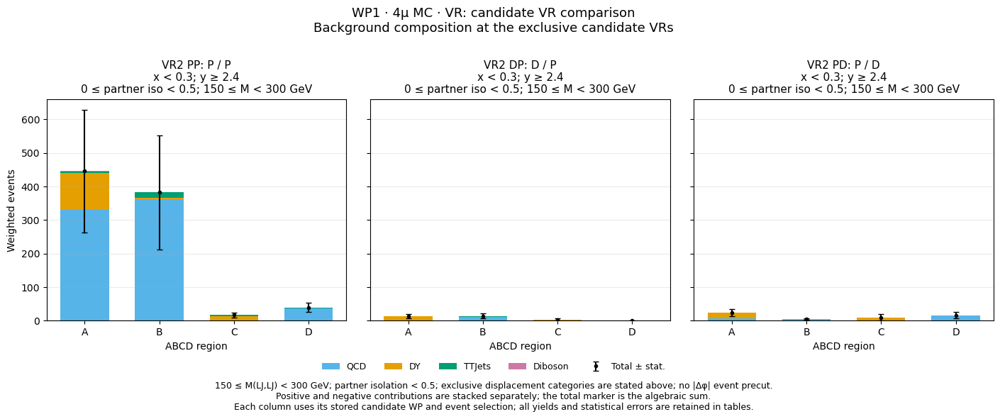

In [21]:
display(figure_lookup['wp1_mc_VR_composition'])


### 4.14. MC ABCD effective counts


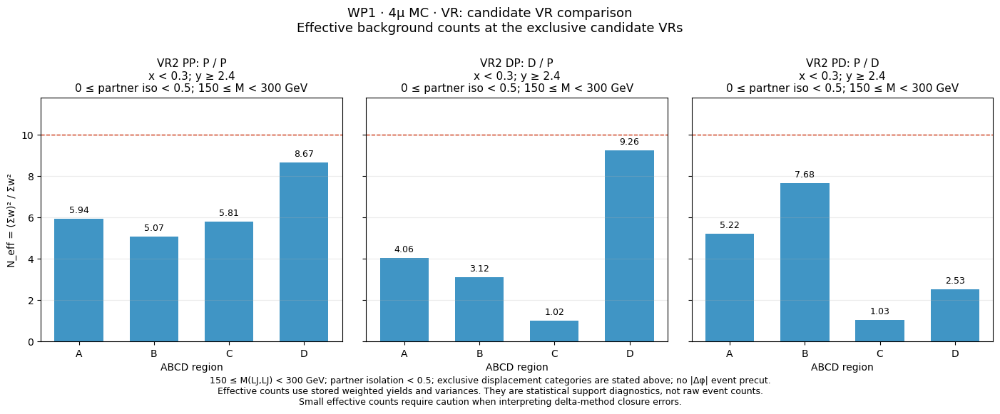

In [22]:
display(figure_lookup['wp1_mc_VR_effective_counts'])


### 4.15. DATA All/A/B/C/D correlations


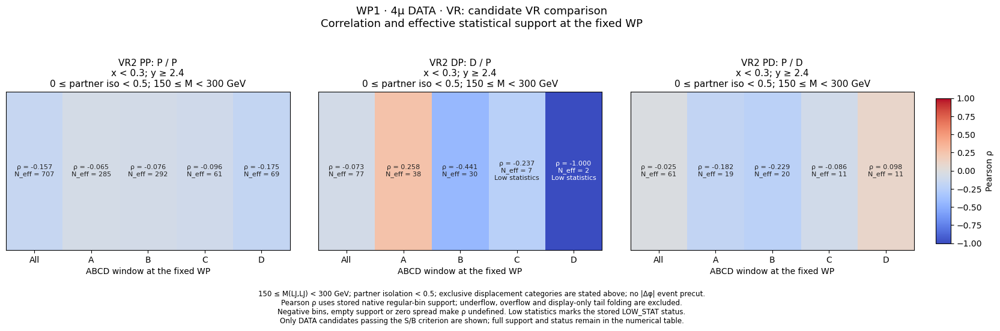

In [23]:
display(figure_lookup['wp1_data_VR_correlations'])


### 4.16. MC All/A/B/C/D correlations


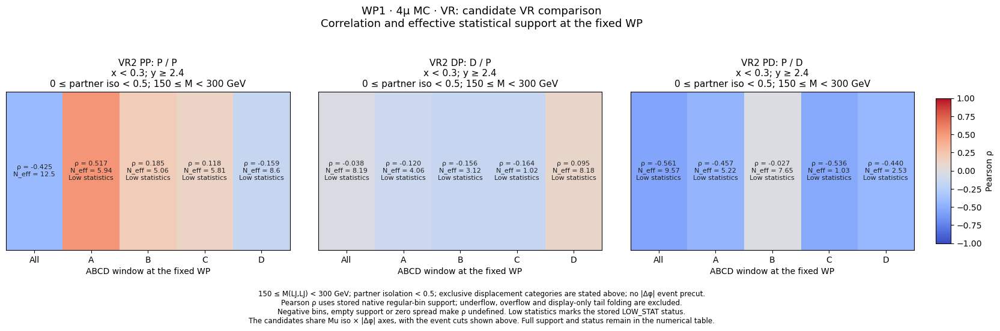

In [24]:
display(figure_lookup['wp1_mc_VR_correlations'])


### 4.17. Nominal MC SR at the same WP

Keep DD, Mjj≥150 GeV, and 0≤partner iso<0.5.
Do not include nominal DATA. Partition the SR at the same (0.30, 2.4) boundaries as the VR.


In [25]:
sr = results['points']['WP1']['sr_reference']
with pd.option_context('display.max_columns', None):
    display(sr['tables']['closure'][['plane', 'source', 'tx', 'ty', 'A', 'B', 'C', 'D',
                                     'pred', 'pred_error', 'kappa', 'kappa_error',
                                     'neff_min', 'status']])


,plane,source,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,status
75,SR,MC,0.3,2.4,3.253182,0.730741,0.002571,0.889517,0.002112,0.003264,1540.277908,2833.601849,1.0,LOW_STAT_SIDEBAND


### 4.18. Nominal MC SR 2D distributions


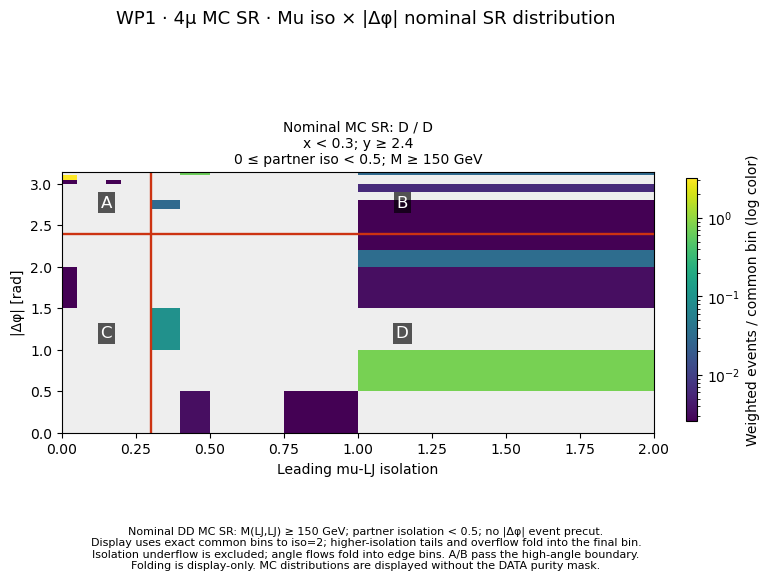

In [26]:
display(figure_lookup['wp1_mc_SR_planes'])


### 4.19. Nominal MC SR ABCD closure


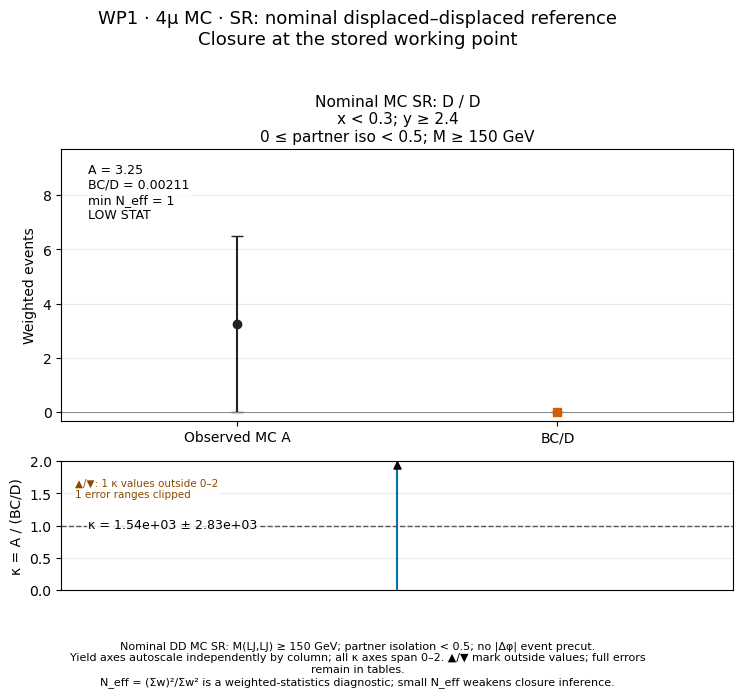

In [27]:
display(figure_lookup['wp1_mc_SR_selected_closure'])


### 4.20. Nominal MC SR isolation boundary scan


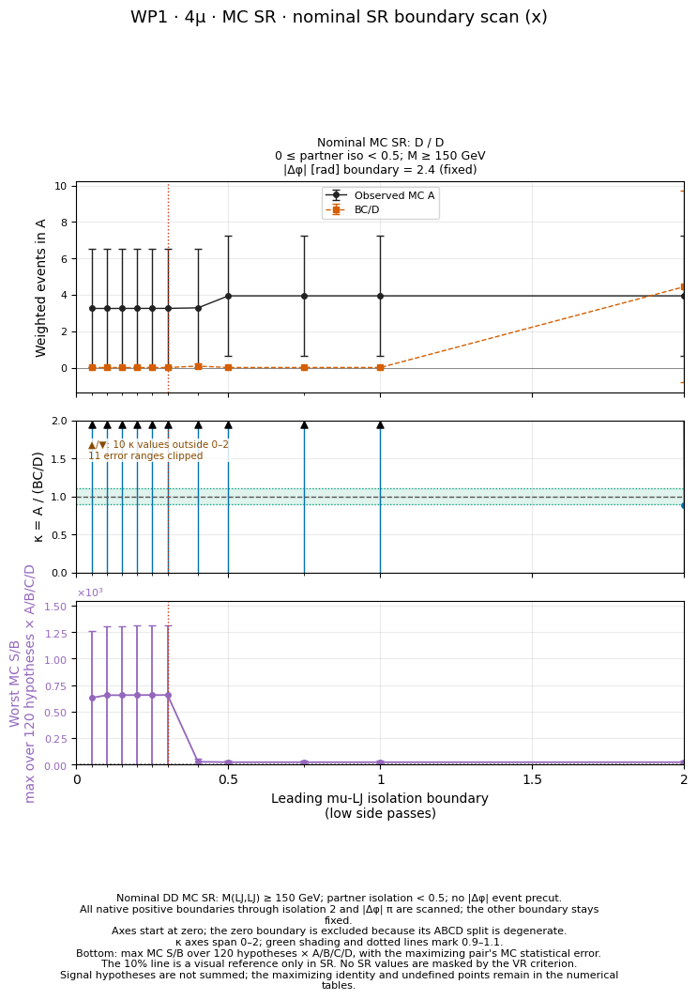

In [28]:
display(figure_lookup['wp1_mc_SR_x_scan'])


### 4.21. Nominal MC SR Δφ boundary scan


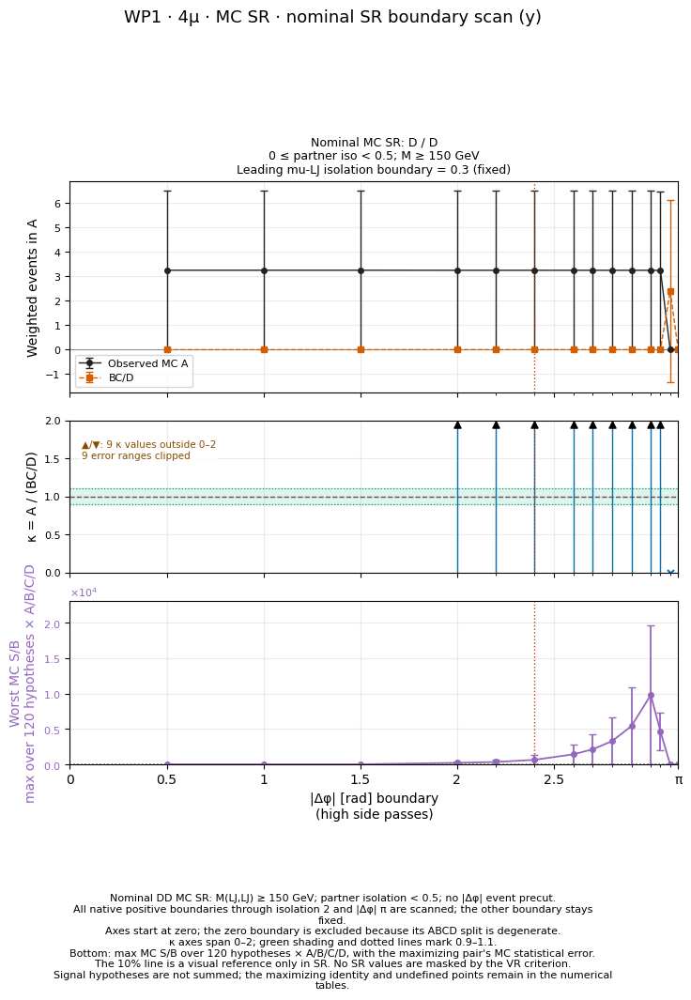

In [29]:
display(figure_lookup['wp1_mc_SR_y_scan'])


### 4.22. Nominal MC SR 154-point κ map


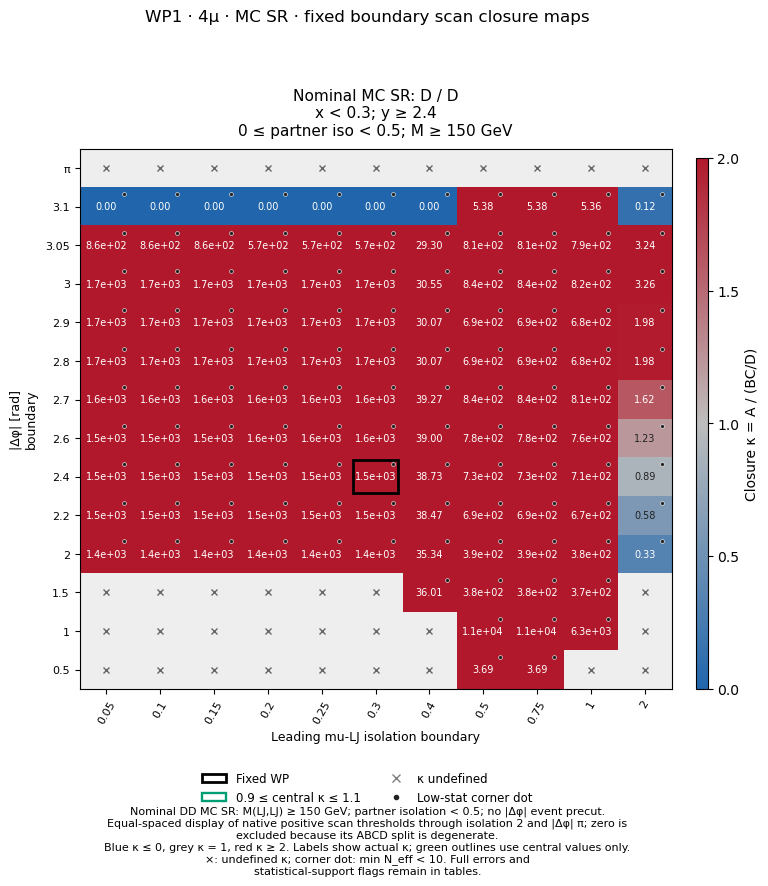

In [30]:
display(figure_lookup['wp1_mc_SR_closure_grid'])


## 5. WP2 — (mu iso, |Δφ|)=(0.25, 2.4)

Apply the **same (0.25, 2.4) boundaries to VR2 PP·DP·PD and the nominal MC SR** in this section.
Fix Δφ at **2.4** for the iso scan and iso at **0.25** for the Δφ scan.
The 154-point 2D κ maps share the same scan; only the selected-WP marker changes.


In [31]:
point = results['points']['WP2']
with pd.option_context('display.max_columns', None):
    display(point['tables']['selection'][['plane', 'state0', 'state1', 'mass_low',
                                         'mass_high', 'partner_iso_high', 'tx', 'ty']])
    display(point['tables']['closure'][['plane', 'source', 'A', 'B', 'C', 'D',
                                       'pred', 'pred_error', 'kappa', 'kappa_error',
                                       'neff_min', 'approved', 'status']])


,plane,state0,state1,mass_low,mass_high,partner_iso_high,tx,ty
0,PP,P,P,150.0,300.0,0.5,0.25,2.4
1,DP,D,P,150.0,300.0,0.5,0.25,2.4
2,PD,P,D,150.0,300.0,0.5,0.25,2.4


,plane,source,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,approved,status
0,PP,MC,446.217383,382.757737,13.686035,43.274893,121.050233,87.656687,3.686217,3.068003,4.427781,True,LOW_STAT_SIDEBAND
1,PP,DATA,251.000000,326.000000,54.000000,76.000000,231.631579,43.175466,1.083617,0.213250,54.000000,True,OK
2,DP,MC,13.085729,14.412884,3.283166,0.534523,88.527351,105.025837,0.147816,0.190100,1.021662,True,LOW_STAT_SIDEBAND
3,DP,DATA,37.000000,31.000000,7.000000,2.000000,108.500000,89.149453,0.341014,0.285749,2.000000,True,LOW_STAT_SIDEBAND
4,PD,MC,23.567710,4.506522,9.620378,16.619304,2.608680,3.196207,9.034343,11.754369,1.021468,True,LOW_STAT_SIDEBAND
5,PD,DATA,16.000000,23.000000,9.000000,13.000000,15.923077,7.661506,1.004831,0.544849,9.000000,True,LOW_STAT_SIDEBAND


### 5.1. MC and DATA closure comparison at the fixed WP


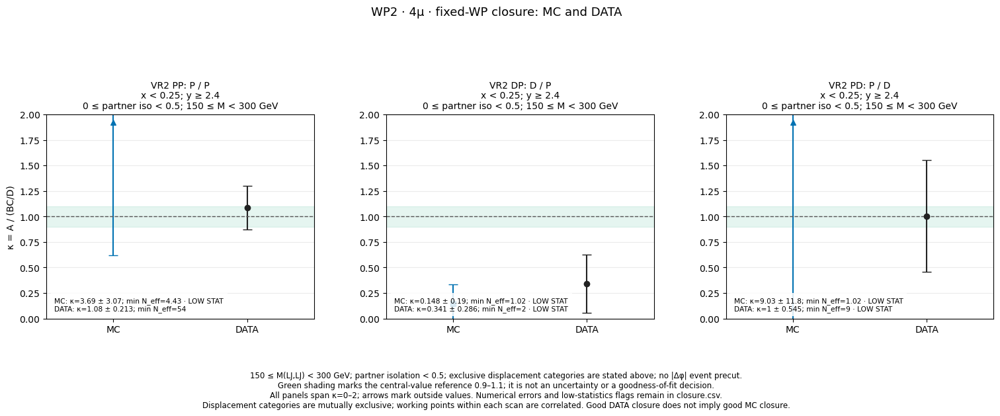

In [32]:
display(figure_lookup['wp2_combined_VR_selected_closure'])


### 5.2. Maximum S/B across 120 signals in each ABCD region


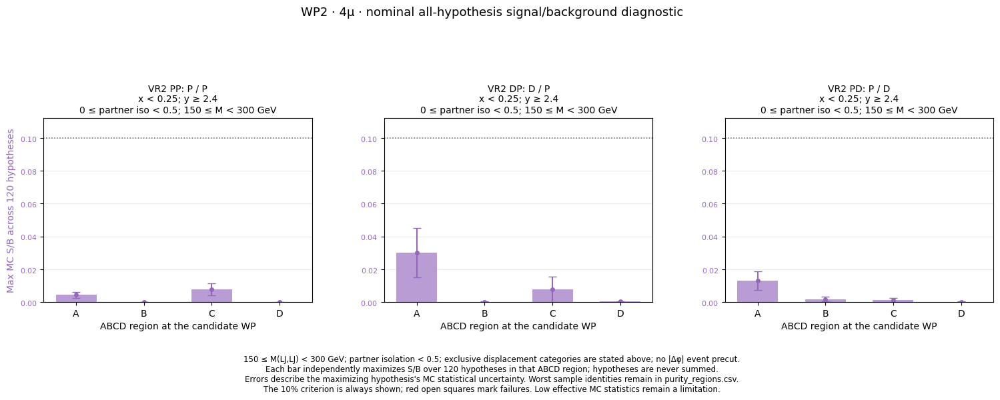

In [33]:
display(figure_lookup['wp2_mc_VR_purity_regions'])


### 5.3. DATA 2D distributions — per-bin blinding


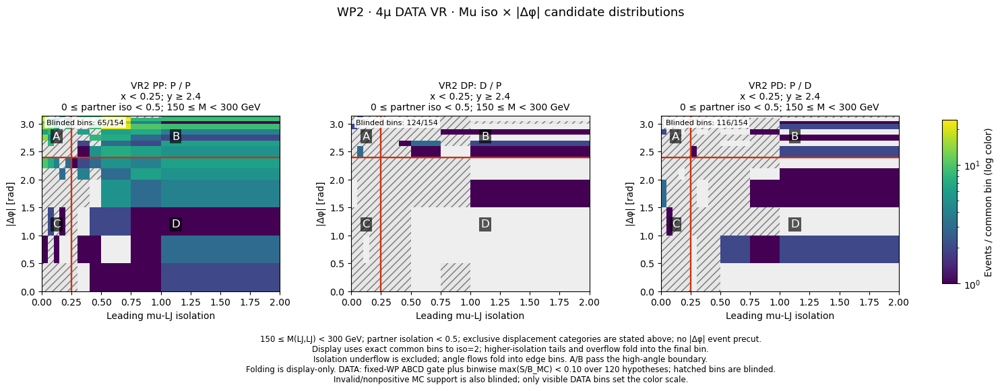

In [34]:
display(figure_lookup['wp2_data_VR_planes'])


### 5.4. DATA observed A, predicted BC/D, and κ


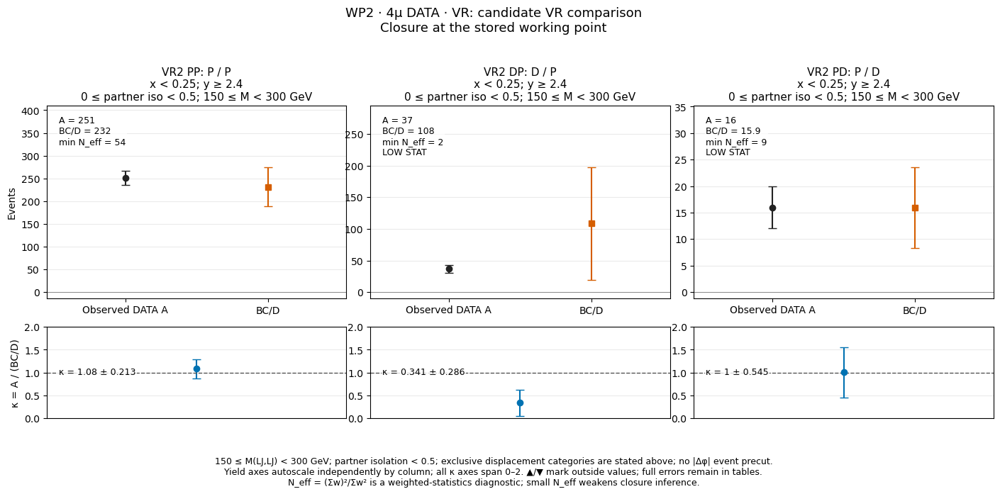

In [35]:
display(figure_lookup['wp2_data_VR_selected_closure'])


### 5.5. DATA isolation boundary scan


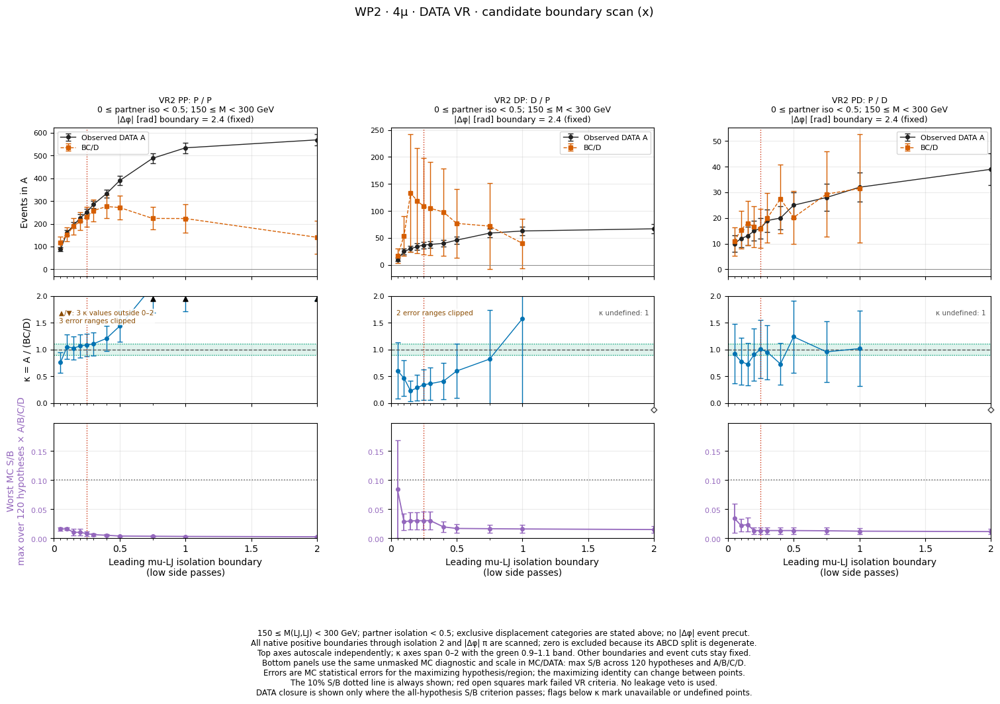

In [36]:
display(figure_lookup['wp2_data_VR_x_scan'])


### 5.6. DATA Δφ boundary scan


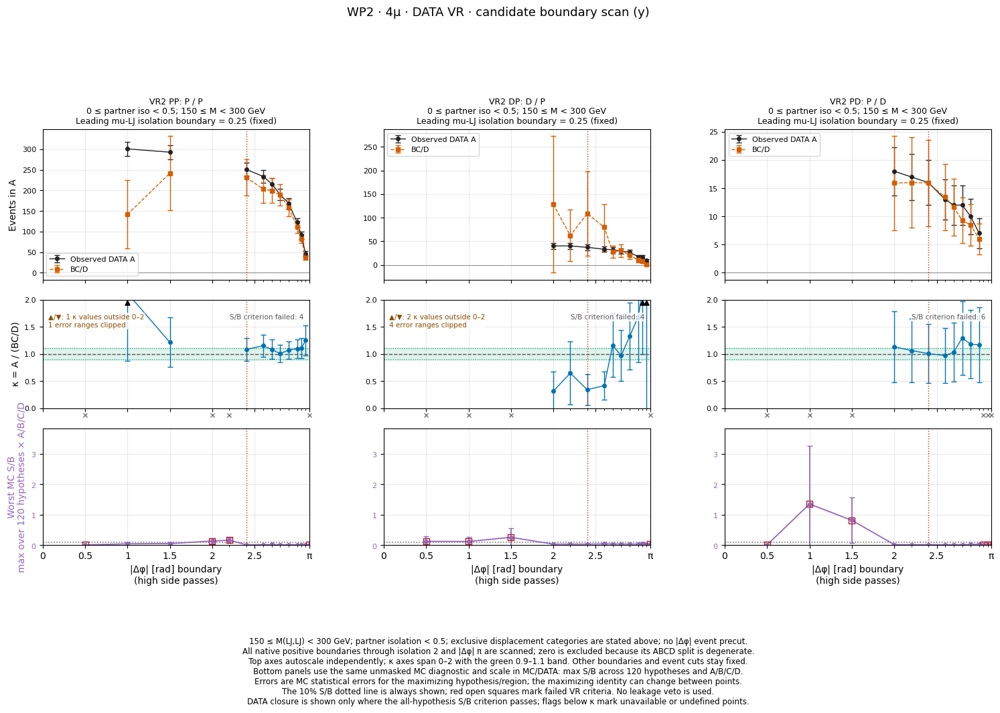

In [37]:
display(figure_lookup['wp2_data_VR_y_scan'])


### 5.7. DATA 154-point κ map


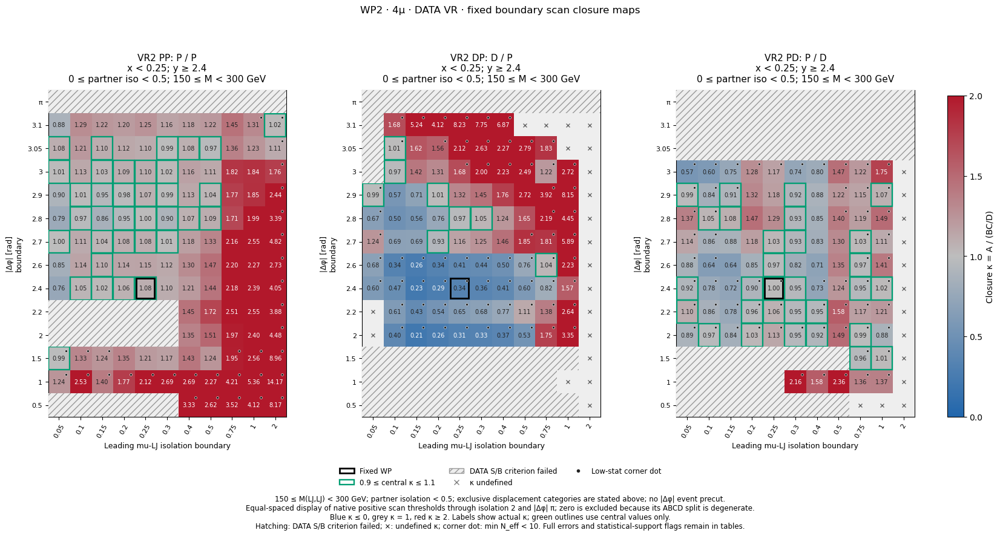

In [38]:
display(figure_lookup['wp2_data_VR_closure_grid'])


### 5.8. MC 2D distributions


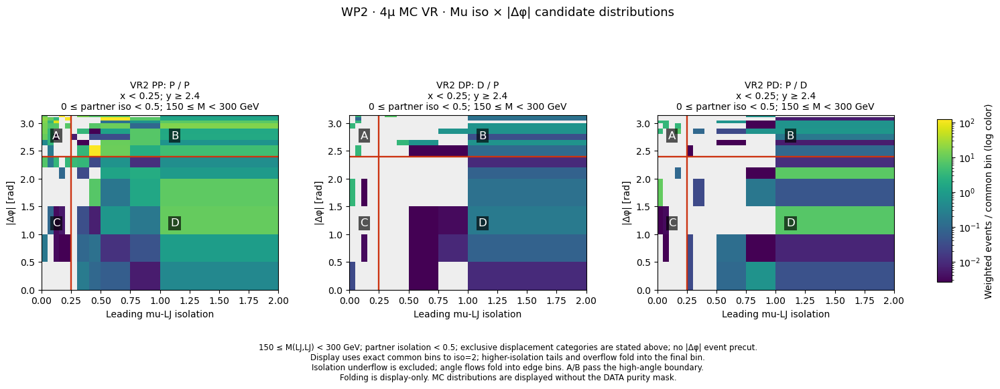

In [39]:
display(figure_lookup['wp2_mc_VR_planes'])


### 5.9. MC observed A, predicted BC/D, and κ


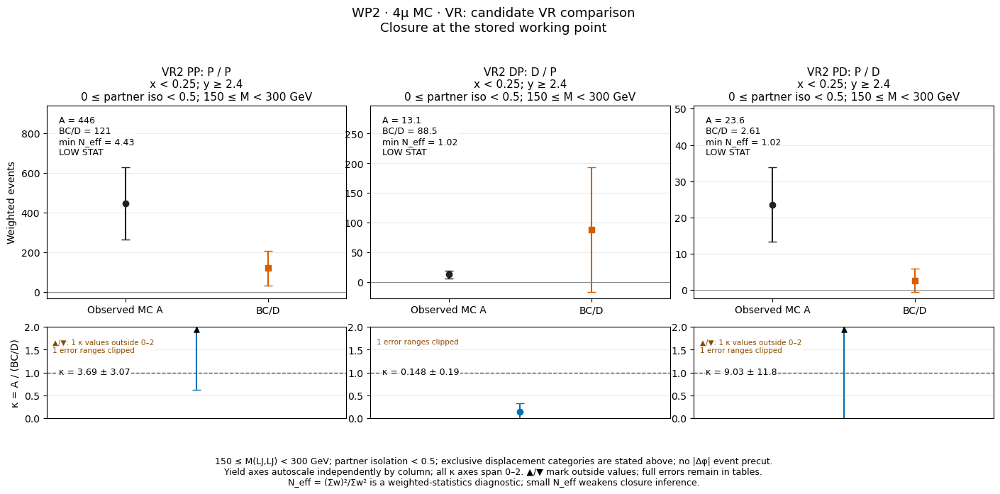

In [40]:
display(figure_lookup['wp2_mc_VR_selected_closure'])


### 5.10. MC isolation boundary scan


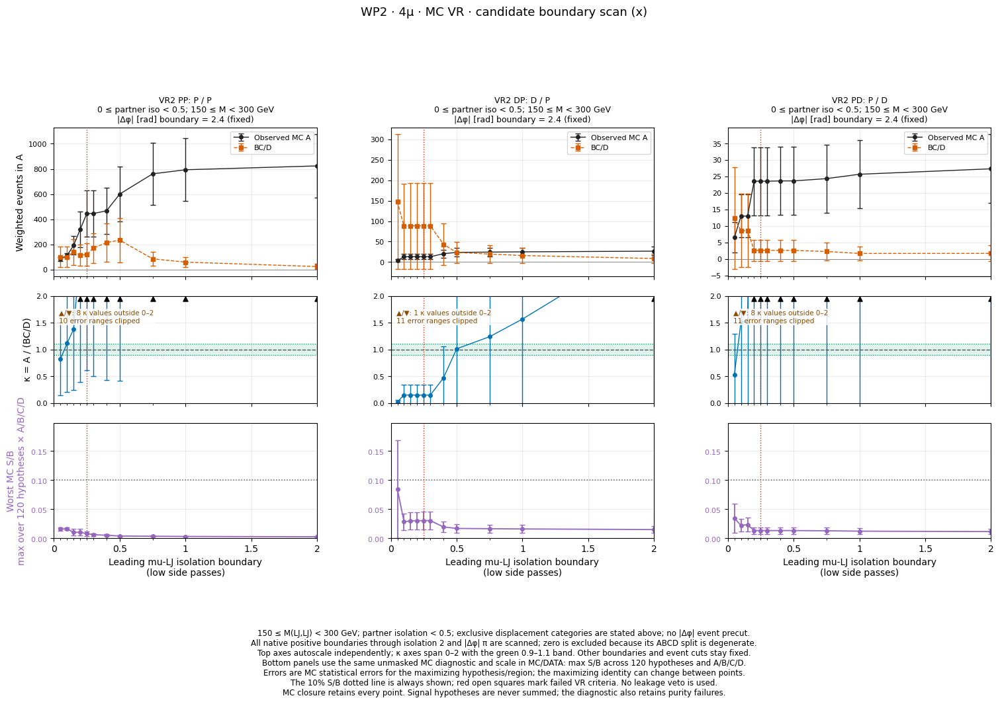

In [41]:
display(figure_lookup['wp2_mc_VR_x_scan'])


### 5.11. MC Δφ boundary scan


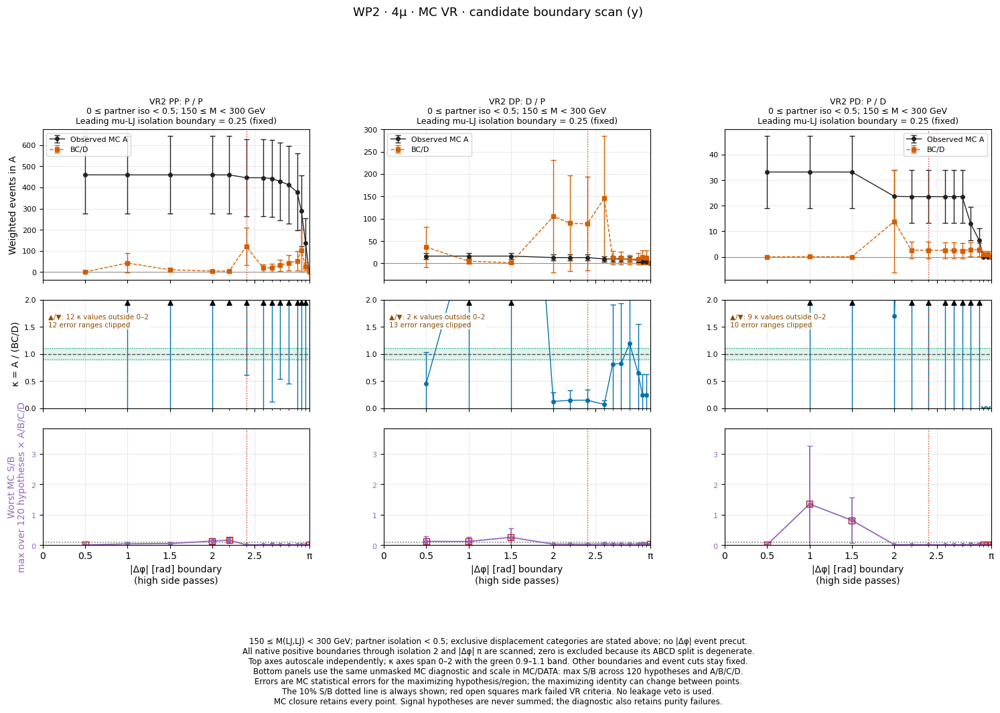

In [42]:
display(figure_lookup['wp2_mc_VR_y_scan'])


### 5.12. MC 154-point κ map


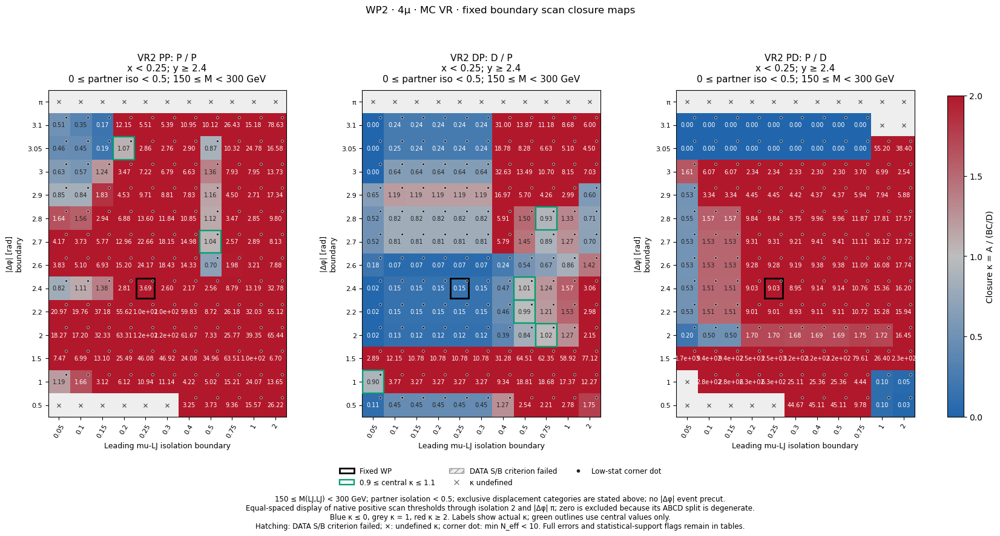

In [43]:
display(figure_lookup['wp2_mc_VR_closure_grid'])


### 5.13. MC background composition


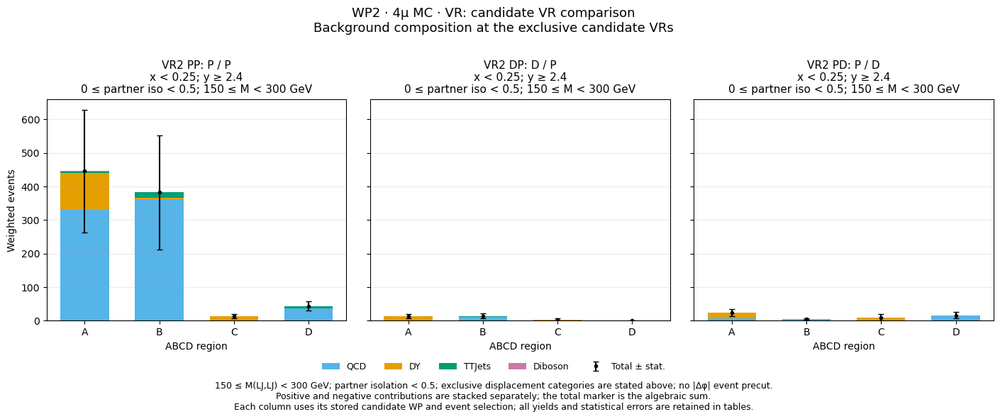

In [44]:
display(figure_lookup['wp2_mc_VR_composition'])


### 5.14. MC ABCD effective counts


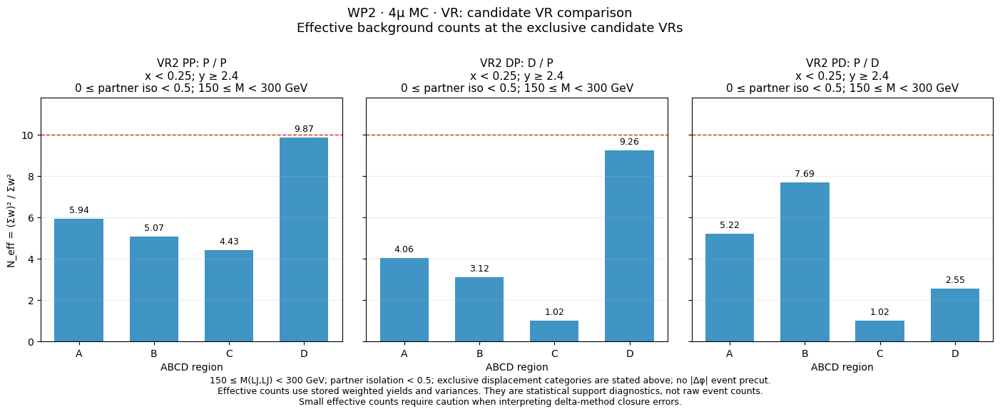

In [45]:
display(figure_lookup['wp2_mc_VR_effective_counts'])


### 5.15. DATA All/A/B/C/D correlations


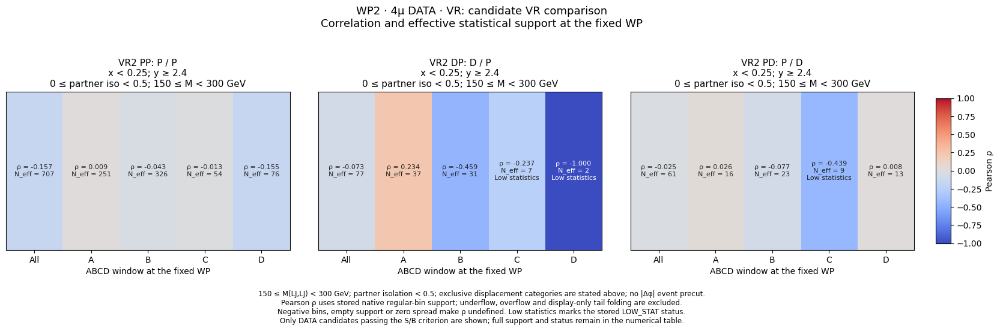

In [46]:
display(figure_lookup['wp2_data_VR_correlations'])


### 5.16. MC All/A/B/C/D correlations


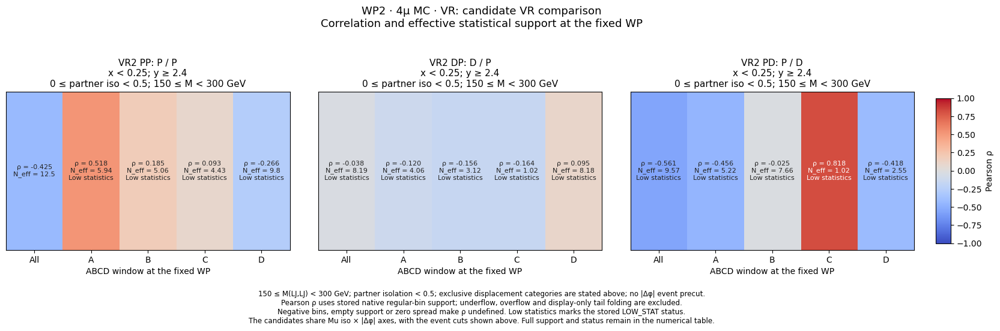

In [47]:
display(figure_lookup['wp2_mc_VR_correlations'])


### 5.17. Nominal MC SR at the same WP

Keep DD, Mjj≥150 GeV, and 0≤partner iso<0.5.
Do not include nominal DATA. Partition the SR at the same (0.25, 2.4) boundaries as the VR.


In [48]:
sr = results['points']['WP2']['sr_reference']
with pd.option_context('display.max_columns', None):
    display(sr['tables']['closure'][['plane', 'source', 'tx', 'ty', 'A', 'B', 'C', 'D',
                                     'pred', 'pred_error', 'kappa', 'kappa_error',
                                     'neff_min', 'status']])


,plane,source,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,status
61,SR,MC,0.25,2.4,3.253182,0.730741,0.002571,0.889517,0.002112,0.003264,1540.277908,2833.601849,1.0,LOW_STAT_SIDEBAND


### 5.18. Nominal MC SR 2D distributions


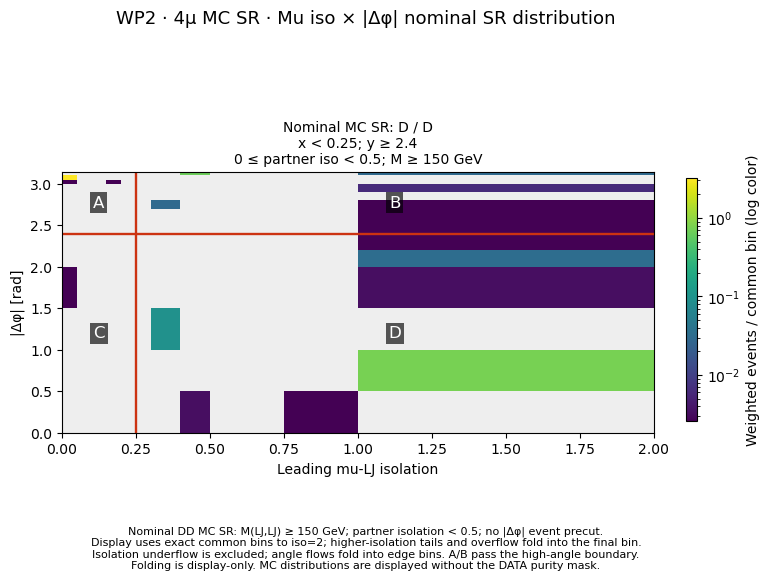

In [49]:
display(figure_lookup['wp2_mc_SR_planes'])


### 5.19. Nominal MC SR ABCD closure


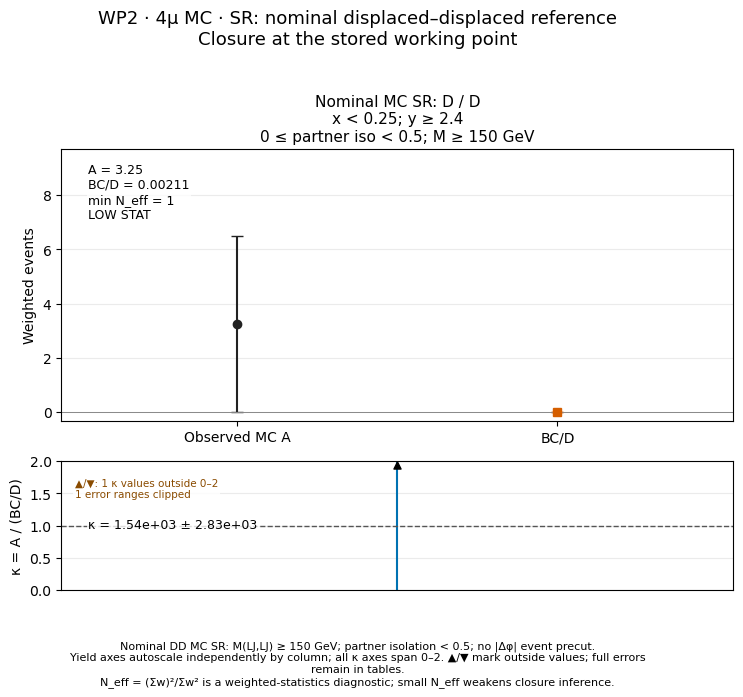

In [50]:
display(figure_lookup['wp2_mc_SR_selected_closure'])


### 5.20. Nominal MC SR isolation boundary scan


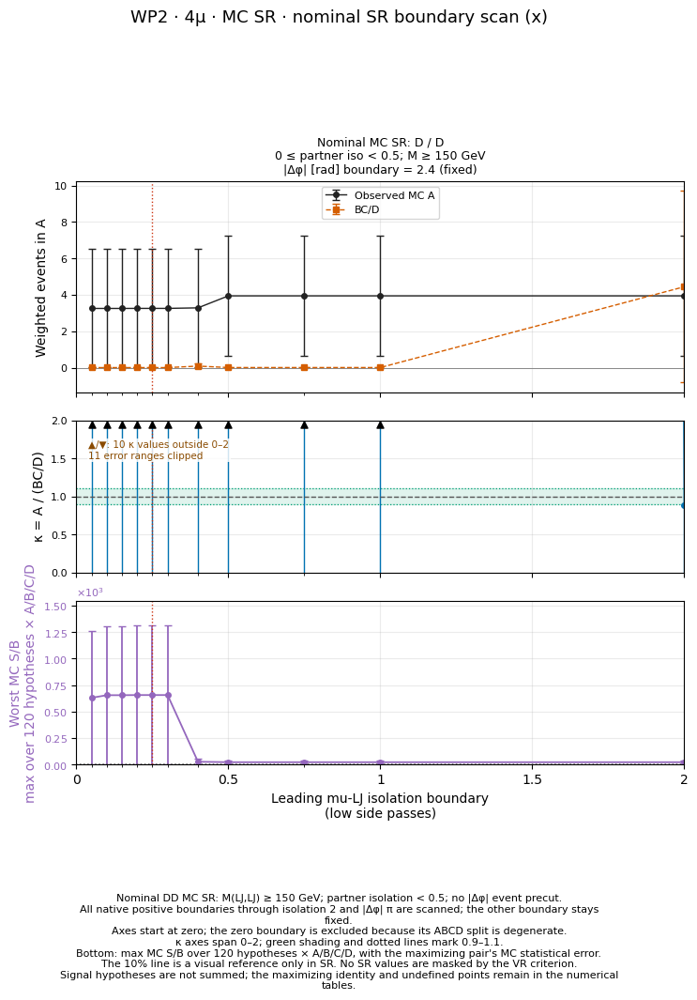

In [51]:
display(figure_lookup['wp2_mc_SR_x_scan'])


### 5.21. Nominal MC SR Δφ boundary scan


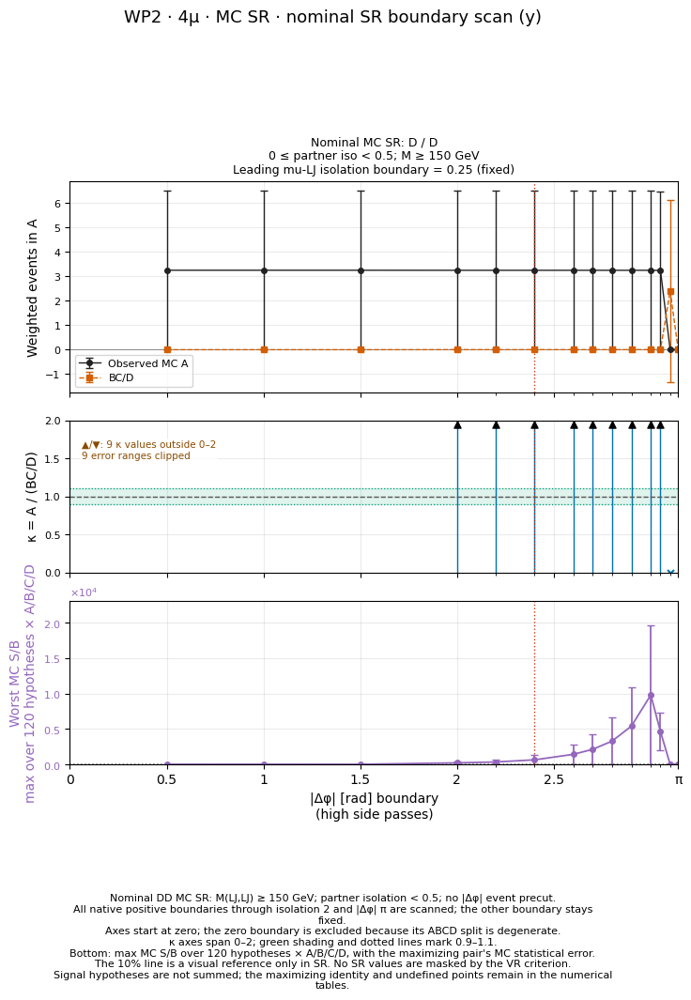

In [52]:
display(figure_lookup['wp2_mc_SR_y_scan'])


### 5.22. Nominal MC SR 154-point κ map


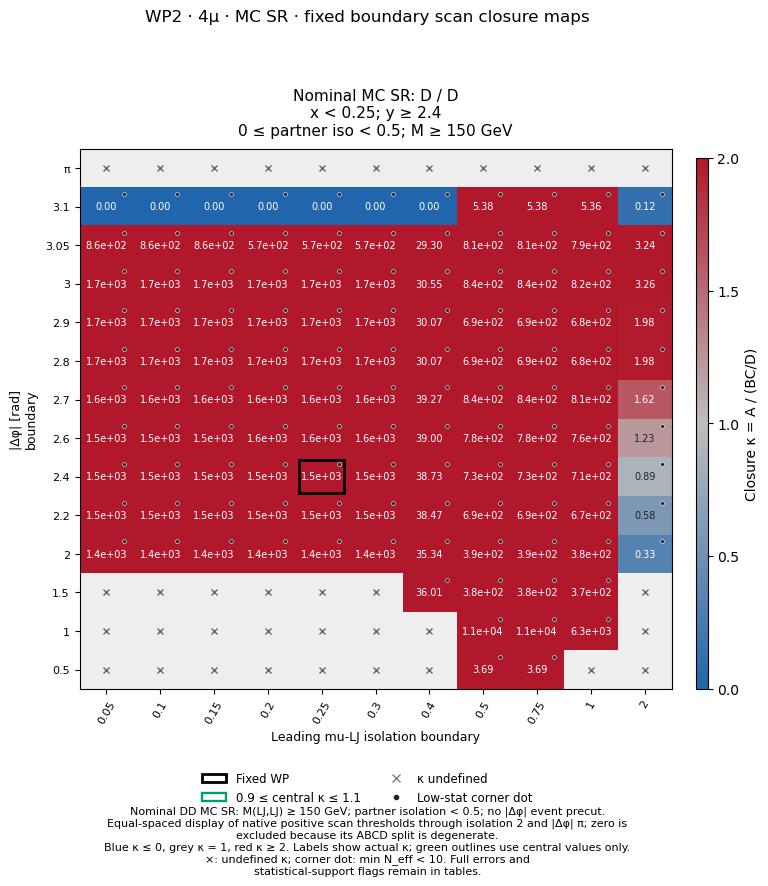

In [53]:
display(figure_lookup['wp2_mc_SR_closure_grid'])


## 6. WP3 — (mu iso, |Δφ|)=(0.40, 2.4)

Apply the **same (0.40, 2.4) boundaries to VR2 PP·DP·PD and the nominal MC SR** in this section.
Fix Δφ at **2.4** for the iso scan and iso at **0.40** for the Δφ scan.
The 154-point 2D κ maps share the same scan; only the selected-WP marker changes.


In [54]:
point = results['points']['WP3']
with pd.option_context('display.max_columns', None):
    display(point['tables']['selection'][['plane', 'state0', 'state1', 'mass_low',
                                         'mass_high', 'partner_iso_high', 'tx', 'ty']])
    display(point['tables']['closure'][['plane', 'source', 'A', 'B', 'C', 'D',
                                       'pred', 'pred_error', 'kappa', 'kappa_error',
                                       'neff_min', 'approved', 'status']])


,plane,state0,state1,mass_low,mass_high,partner_iso_high,tx,ty
0,PP,P,P,150.0,300.0,0.5,0.4,2.4
1,DP,D,P,150.0,300.0,0.5,0.4,2.4
2,PD,P,D,150.0,300.0,0.5,0.4,2.4


,plane,source,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,approved,status
0,PP,MC,467.410337,361.564783,21.266258,35.694670,215.413956,151.358159,2.169824,1.746279,4.544739,True,LOW_STAT_SIDEBAND
1,PP,DATA,333.000000,244.000000,69.000000,61.000000,276.000000,51.623479,1.206522,0.235156,61.000000,True,OK
2,DP,MC,20.413241,7.085372,3.283166,0.534523,43.520036,50.457316,0.469054,0.588538,1.021662,True,LOW_STAT_SIDEBAND
3,DP,DATA,40.000000,28.000000,7.000000,2.000000,98.000000,80.727938,0.408163,0.342364,2.000000,True,LOW_STAT_SIDEBAND
4,PD,MC,23.663851,4.410381,9.707901,16.531781,2.589893,3.164607,9.137000,11.854010,1.040109,True,LOW_STAT_SIDEBAND
5,PD,DATA,20.000000,19.000000,13.000000,9.000000,27.444444,13.463612,0.728745,0.392891,9.000000,True,LOW_STAT_SIDEBAND


### 6.1. MC and DATA closure comparison at the fixed WP


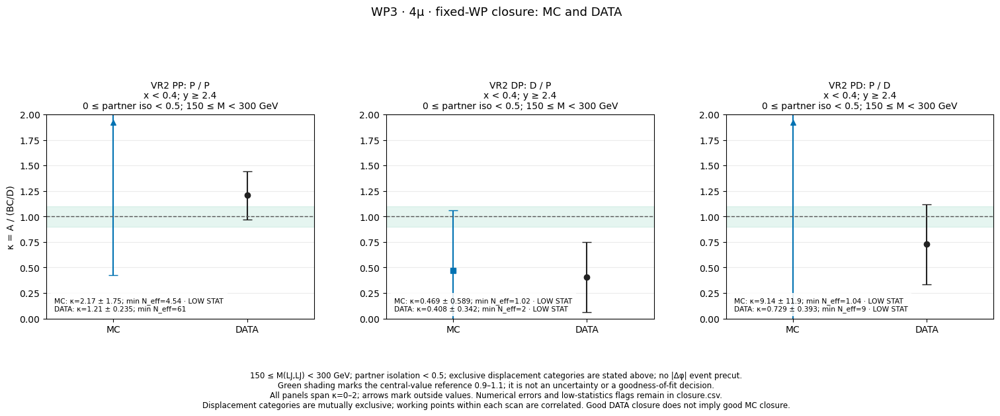

In [55]:
display(figure_lookup['wp3_combined_VR_selected_closure'])


### 6.2. Maximum S/B across 120 signals in each ABCD region


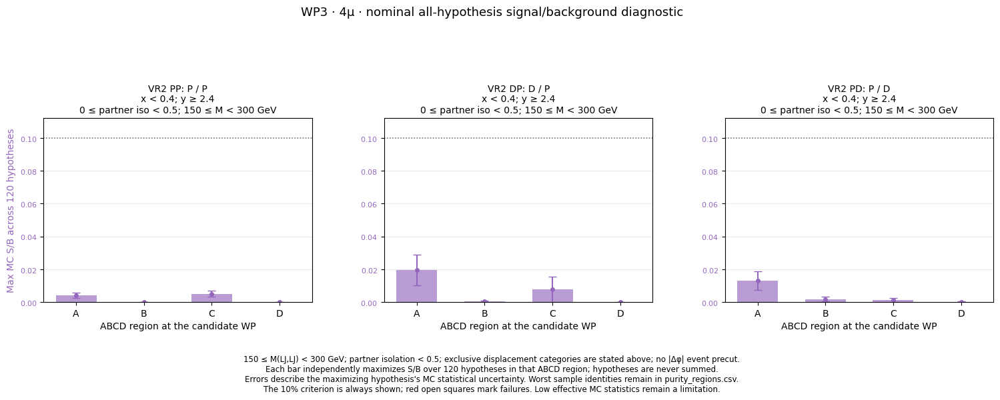

In [56]:
display(figure_lookup['wp3_mc_VR_purity_regions'])


### 6.3. DATA 2D distributions — per-bin blinding


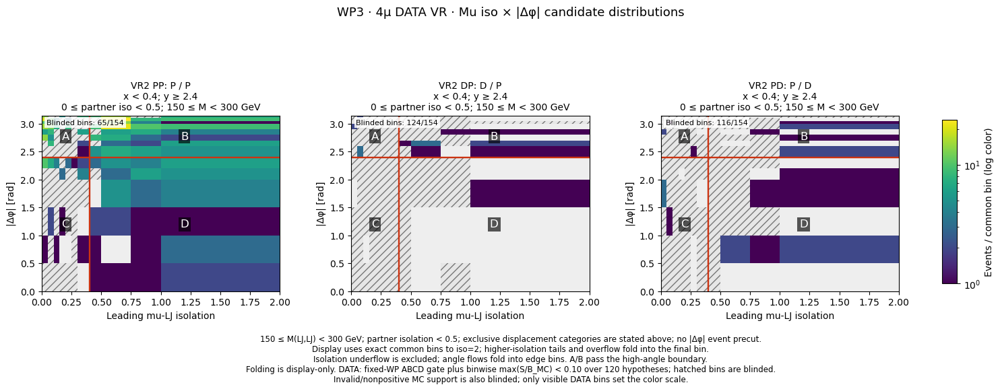

In [57]:
display(figure_lookup['wp3_data_VR_planes'])


### 6.4. DATA observed A, predicted BC/D, and κ


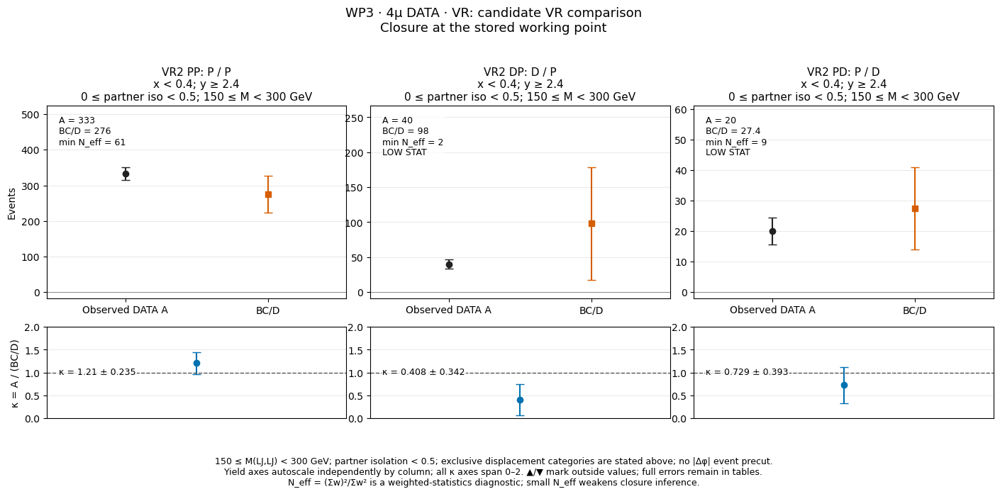

In [58]:
display(figure_lookup['wp3_data_VR_selected_closure'])


### 6.5. DATA isolation boundary scan


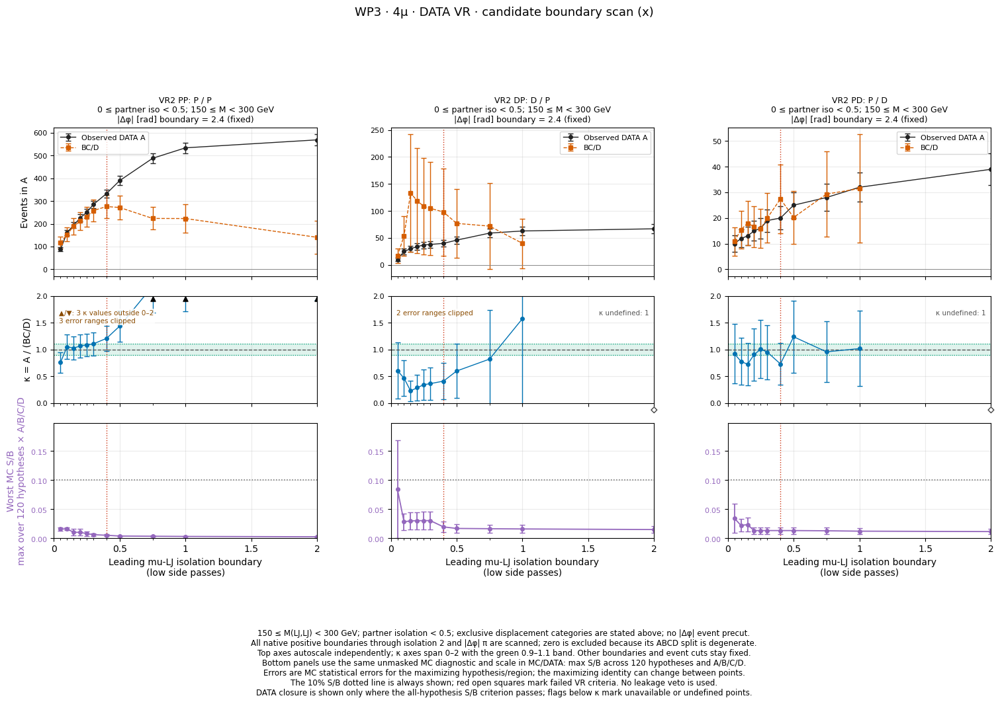

In [59]:
display(figure_lookup['wp3_data_VR_x_scan'])


### 6.6. DATA Δφ boundary scan


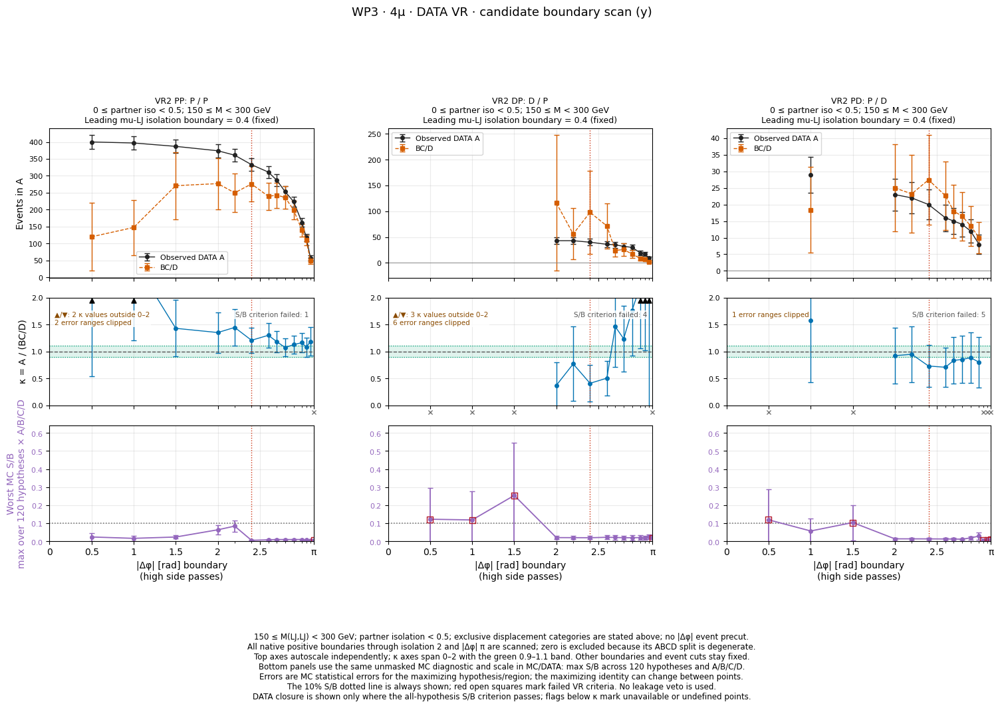

In [60]:
display(figure_lookup['wp3_data_VR_y_scan'])


### 6.7. DATA 154-point κ map


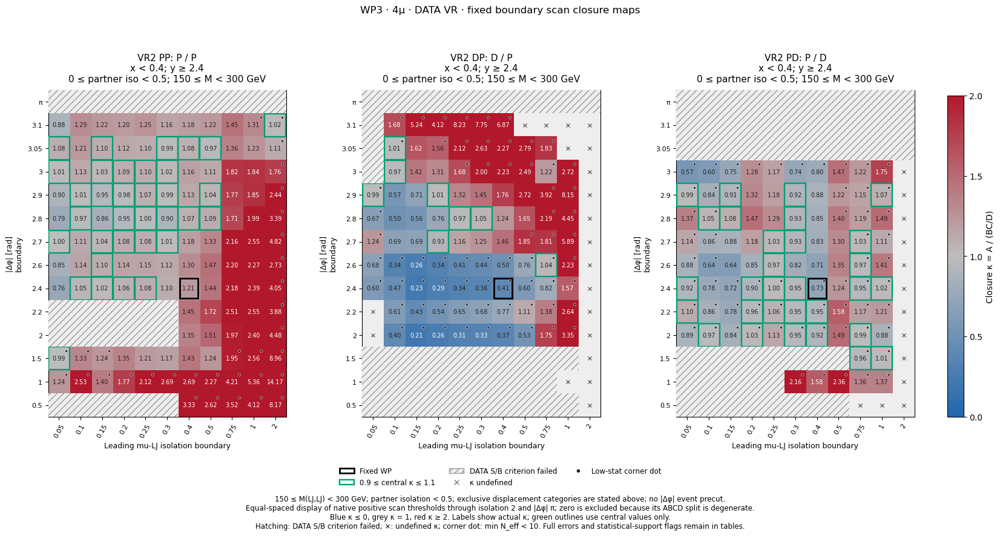

In [61]:
display(figure_lookup['wp3_data_VR_closure_grid'])


### 6.8. MC 2D distributions


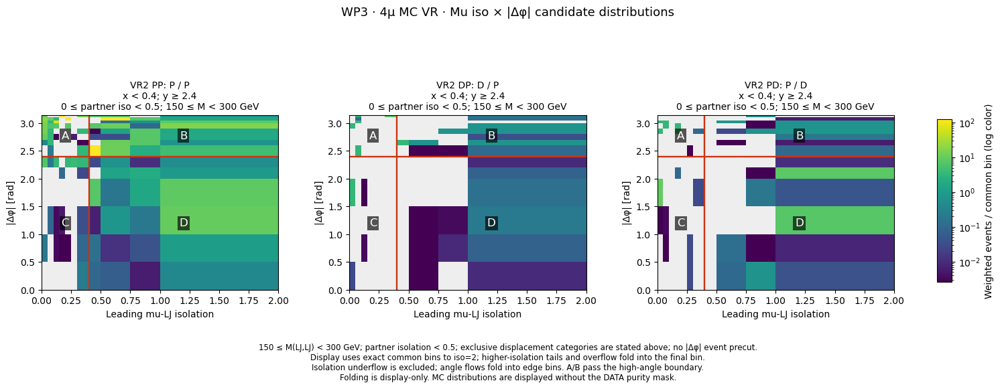

In [62]:
display(figure_lookup['wp3_mc_VR_planes'])


### 6.9. MC observed A, predicted BC/D, and κ


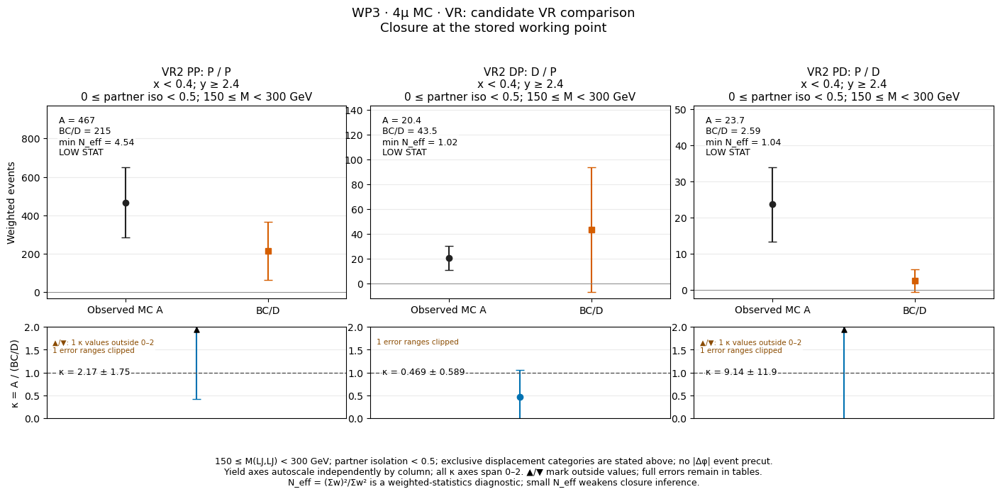

In [63]:
display(figure_lookup['wp3_mc_VR_selected_closure'])


### 6.10. MC isolation boundary scan


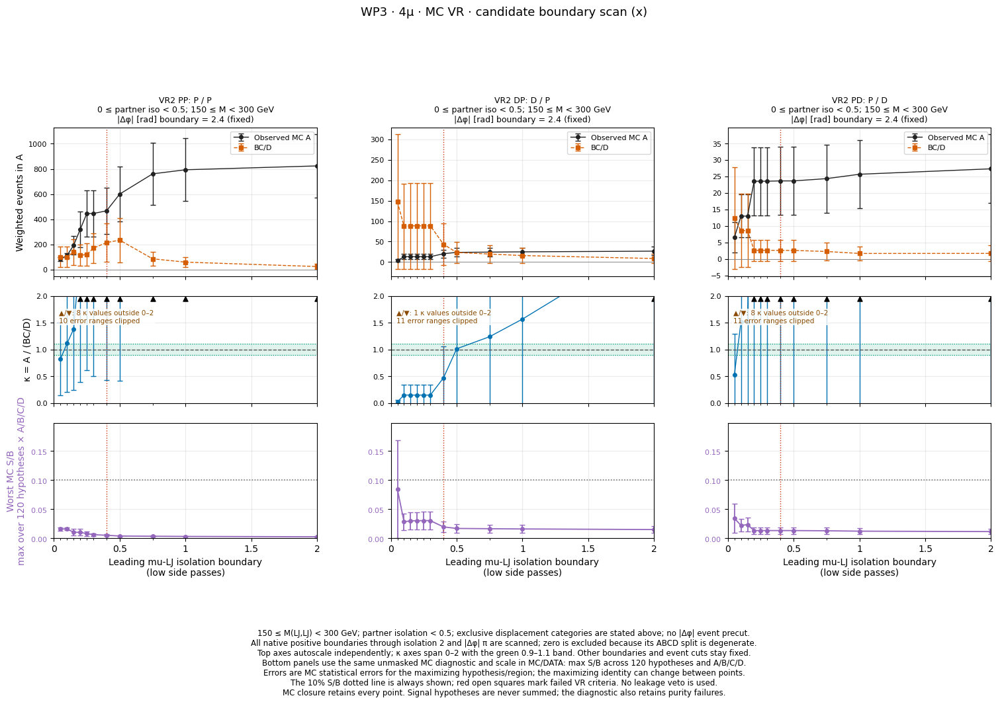

In [64]:
display(figure_lookup['wp3_mc_VR_x_scan'])


### 6.11. MC Δφ boundary scan


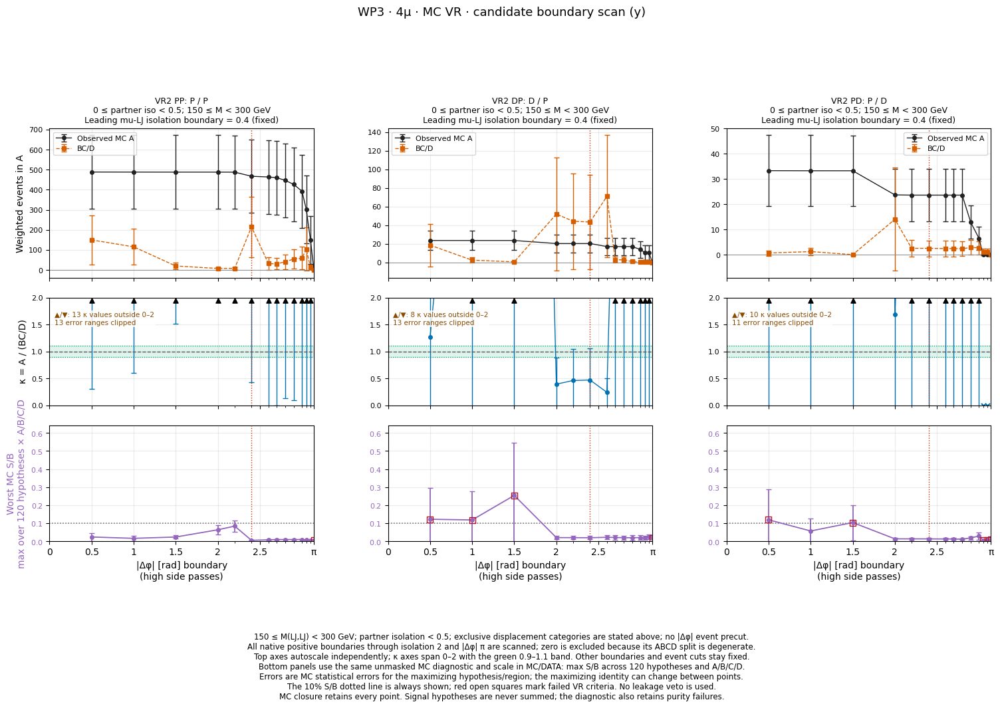

In [65]:
display(figure_lookup['wp3_mc_VR_y_scan'])


### 6.12. MC 154-point κ map


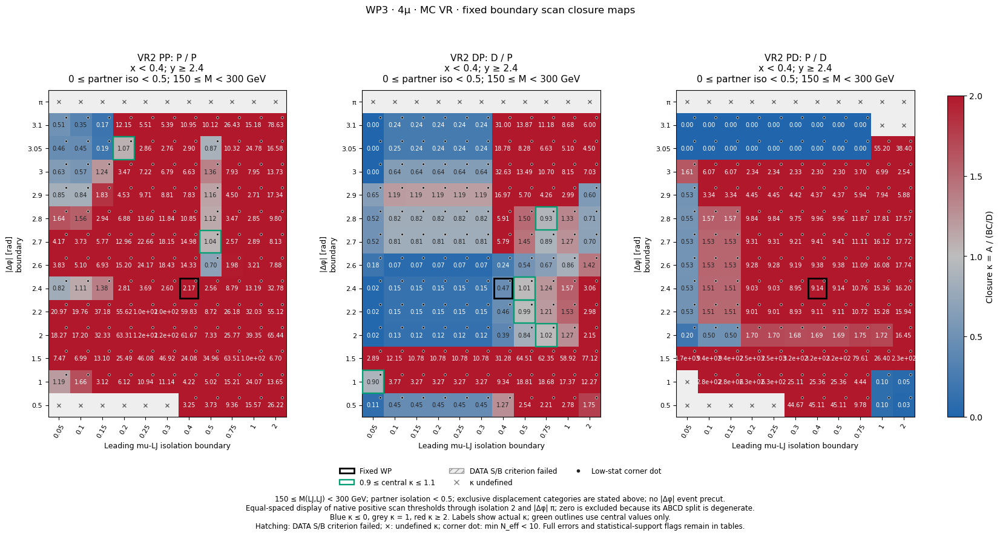

In [66]:
display(figure_lookup['wp3_mc_VR_closure_grid'])


### 6.13. MC background composition


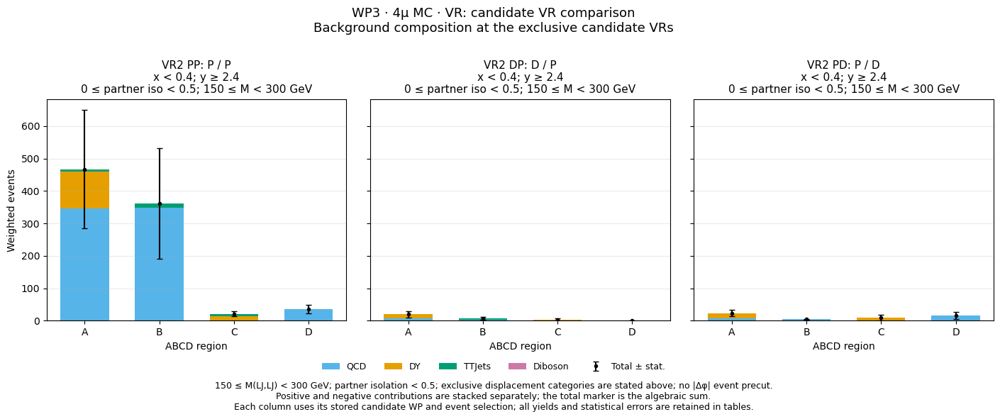

In [67]:
display(figure_lookup['wp3_mc_VR_composition'])


### 6.14. MC ABCD effective counts


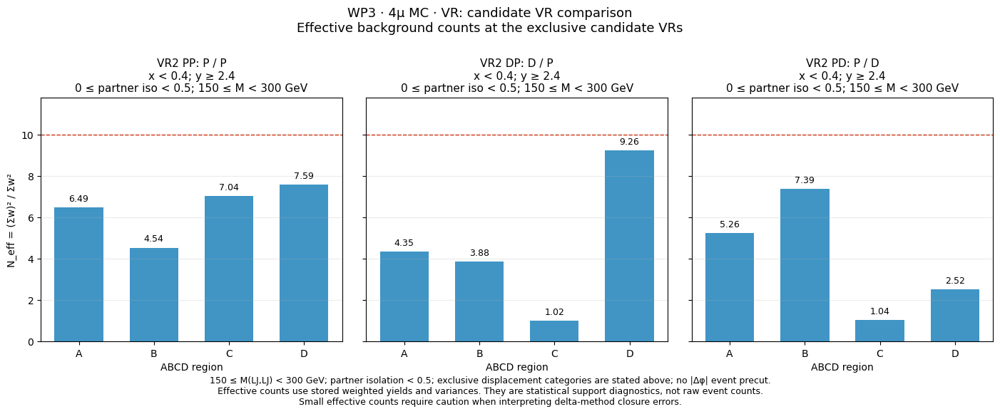

In [68]:
display(figure_lookup['wp3_mc_VR_effective_counts'])


### 6.15. DATA All/A/B/C/D correlations


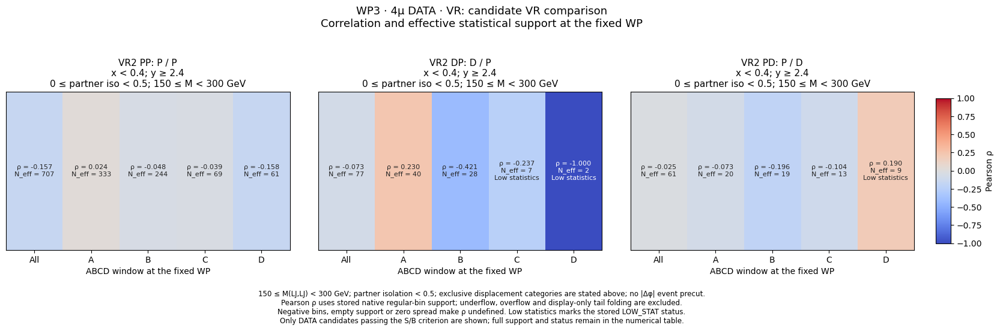

In [69]:
display(figure_lookup['wp3_data_VR_correlations'])


### 6.16. MC All/A/B/C/D correlations


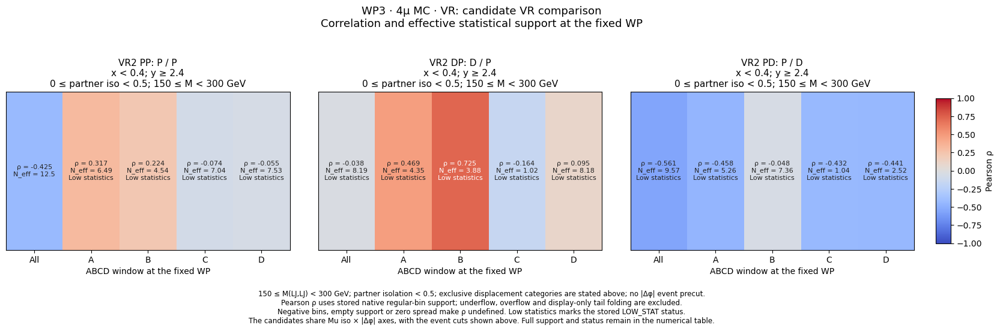

In [70]:
display(figure_lookup['wp3_mc_VR_correlations'])


### 6.17. Nominal MC SR at the same WP

Keep DD, Mjj≥150 GeV, and 0≤partner iso<0.5.
Do not include nominal DATA. Partition the SR at the same (0.40, 2.4) boundaries as the VR.


In [71]:
sr = results['points']['WP3']['sr_reference']
with pd.option_context('display.max_columns', None):
    display(sr['tables']['closure'][['plane', 'source', 'tx', 'ty', 'A', 'B', 'C', 'D',
                                     'pred', 'pred_error', 'kappa', 'kappa_error',
                                     'neff_min', 'status']])


,plane,source,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,status
89,SR,MC,0.4,2.4,3.282356,0.701566,0.096141,0.795946,0.084741,0.13483,38.7338,72.575958,1.021159,LOW_STAT_SIDEBAND


### 6.18. Nominal MC SR 2D distributions


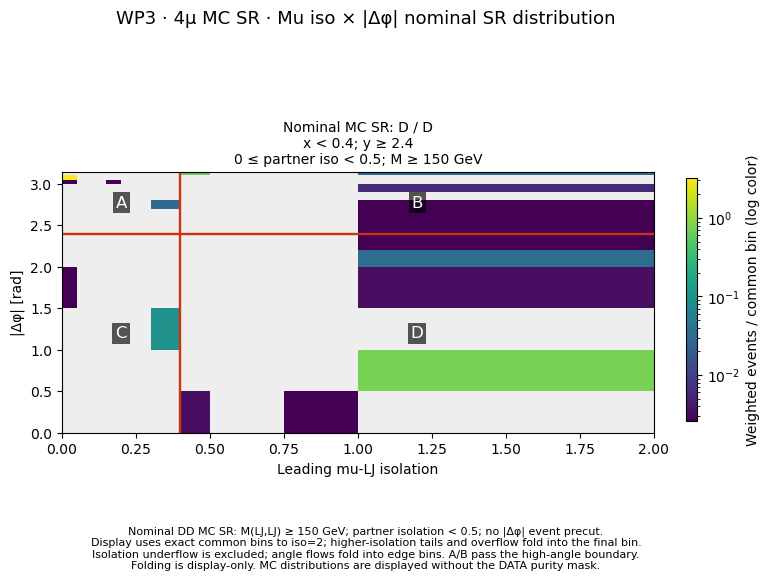

In [72]:
display(figure_lookup['wp3_mc_SR_planes'])


### 6.19. Nominal MC SR ABCD closure


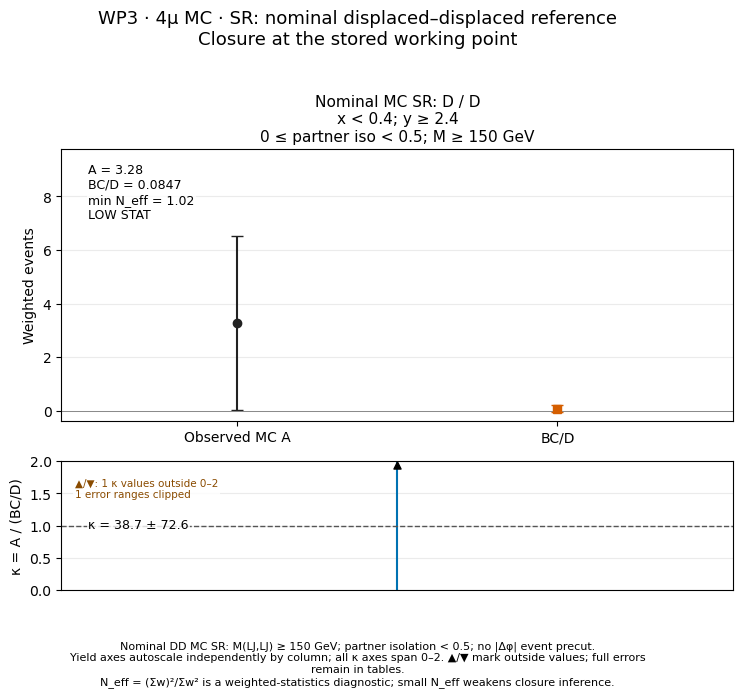

In [73]:
display(figure_lookup['wp3_mc_SR_selected_closure'])


### 6.20. Nominal MC SR isolation boundary scan


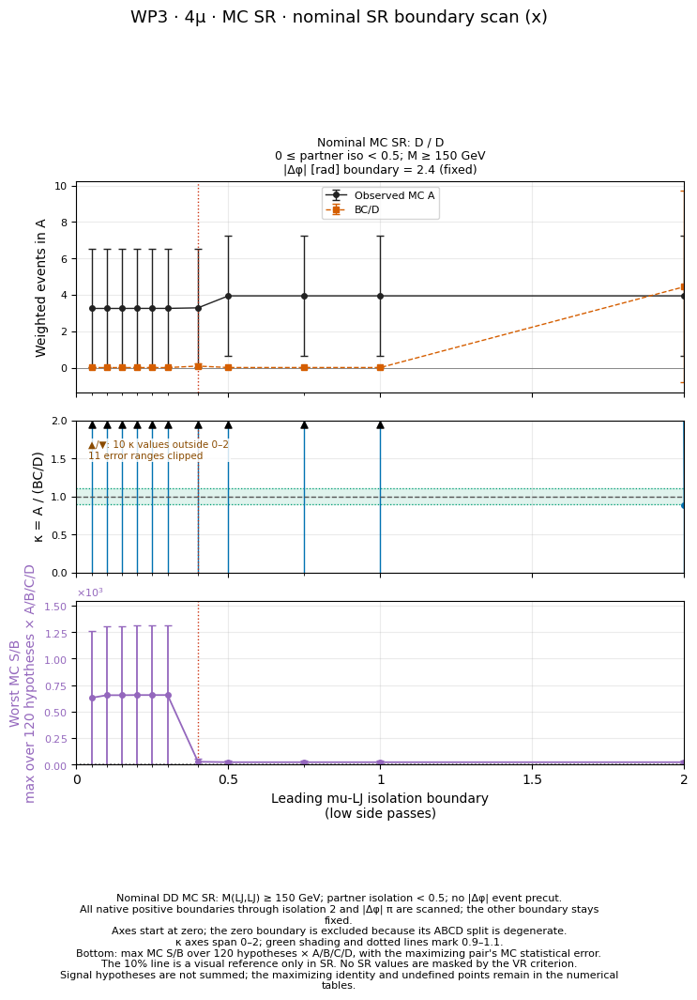

In [74]:
display(figure_lookup['wp3_mc_SR_x_scan'])


### 6.21. Nominal MC SR Δφ boundary scan


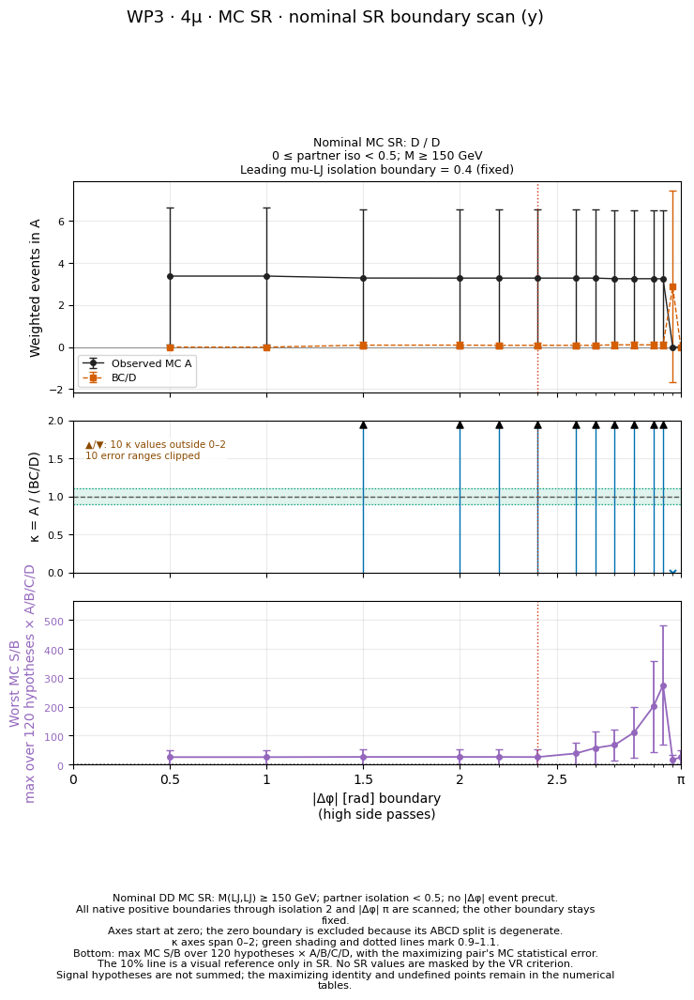

In [75]:
display(figure_lookup['wp3_mc_SR_y_scan'])


### 6.22. Nominal MC SR 154-point κ map


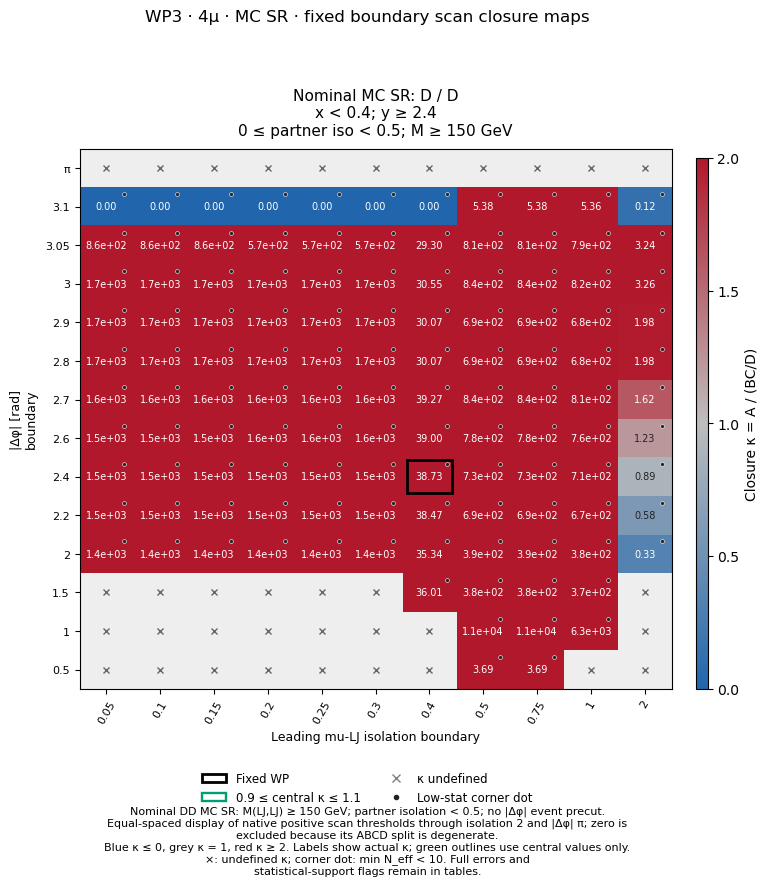

In [76]:
display(figure_lookup['wp3_mc_SR_closure_grid'])


## 7. Validation and export

Check that each WP uses identical SR and VR boundaries, scans hold the other axis fixed, and ABCD yields agree between the full grid and direct sums.
Check the DATA gate and displayed-bin mask as well. Retain the MC SR regression and native-bin partition checks against the original reference.

Save three summary PNGs, a complete 66-page slide PDF containing all figures,
reference and candidate values, per-signal significance, purity tables, and the input manifest in this notebook's dedicated outputs folder.
Do not record masked 2D DATA bin values in a new audit table.

Preserve all 66 figures in both this notebook and the complete vector PDF. Save only the three summary figures as separate PNGs at 100dpi; do not duplicate WP-specific PNGs or individual PDFs. Recalculate the full 154-point signal grid from the original inputs without writing duplicate CSVs. Save per-hypothesis values for all 120 signals at the reference and three WPs in `signal_significance.csv`.


In [77]:
export_wp_comparison(results, CONFIG, figures)
display(Markdown(f'[PNG figure index]({OUTPUT_DIR.name}/figure_manifest.csv)'))
display(Markdown(f'[Output directory]({OUTPUT_DIR.name}/)'))


Saved: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_finalize/06_4mu_WP_comparison_outputs


[PNG figure index](06_4mu_WP_comparison_outputs/figure_manifest.csv)

[Output directory](06_4mu_WP_comparison_outputs/)

## Interpretation and limitations

In the current production, sensitivity differences among the candidates are about 2%, and the SR background MC is dominated by DY with low effective statistics.
Also check the reduced D-region statistics in VR DP for the Δφ=2.4 candidates.
WP3=(0.40, 2.4) is retained because of the alternative metric that includes MC statistical uncertainty.

The three WPs are candidates for further review, not a final analysis WP selection.
Good DATA closure alone does not guarantee MC closure or stable nominal ABCD estimation.
The WPs share events with the existing reference, so do not interpret differences between WPs as independent statistical tests.
